**Applying the Kriging Model to all seperate Sound Maps**

1. Import all necessary things and Store Kriging Model Class in variable.

In [109]:
import importlib
import numpy as np
import matplotlib.pyplot as plt
from extract_sound import prepare_interpolation_data
import Ordinary_Kriging_Model
importlib.reload(Ordinary_Kriging_Model)
from Ordinary_Kriging_Model import ExactAcousticKriging

Kriging_Model = ExactAcousticKriging(safety_margin_db=6.0, peak_boost=True)
no_buffer_Kriging_Model = ExactAcousticKriging(safety_margin_db=0.0, peak_boost=False)

**2. Input the single point source sound map to the Kriging Model**

2.1 Ordinary Kriging Model without additional Buffer

Phones:   5 | Layout: random     | RMSE: 4.44 dB | Worst Under-Prediction: 30.73 dB
Phones:   5 | Layout: grid       | RMSE: 4.32 dB | Worst Under-Prediction: 29.06 dB
Phones:   5 | Layout: clustered  | RMSE: 7.36 dB | Worst Under-Prediction: 23.47 dB
Phones:  10 | Layout: random     | RMSE: 4.45 dB | Worst Under-Prediction: 23.05 dB
Phones:  10 | Layout: grid       | RMSE: 4.72 dB | Worst Under-Prediction: 21.98 dB
Phones:  10 | Layout: clustered  | RMSE: 10.40 dB | Worst Under-Prediction: 8.17 dB
Phones:  20 | Layout: random     | RMSE: 5.75 dB | Worst Under-Prediction: 1.92 dB
Phones:  20 | Layout: grid       | RMSE: 4.18 dB | Worst Under-Prediction: 10.13 dB
Phones:  20 | Layout: clustered  | RMSE: 6.38 dB | Worst Under-Prediction: 22.71 dB
Phones:  50 | Layout: random     | RMSE: 4.68 dB | Worst Under-Prediction: 1.64 dB
Phones:  50 | Layout: grid       | RMSE: 3.97 dB | Worst Under-Prediction: 0.00 dB
Phones:  50 | Layout: clustered  | RMSE: 6.03 dB | Worst Under-Prediction: 22.8

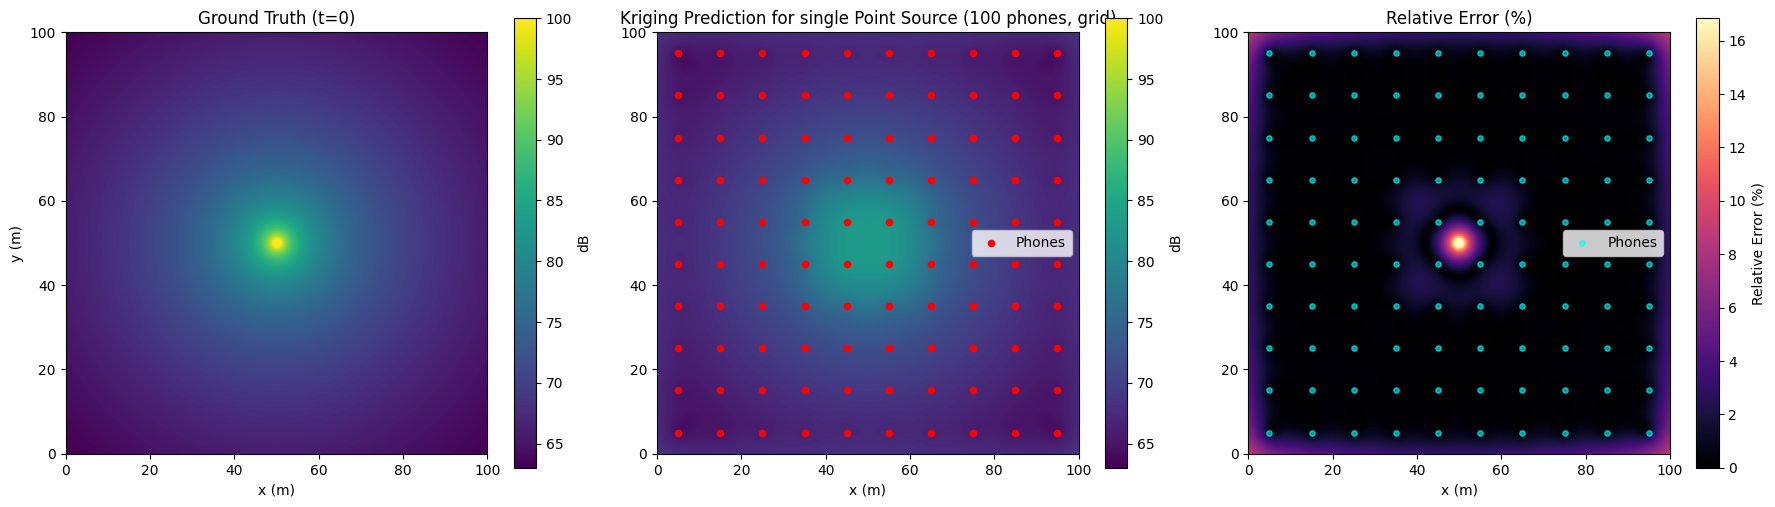

In [112]:
import point_source as sound_map

# 1. Load the sound maps and grid
sound_maps = sound_map.sound_maps
x = sound_map.x
y = sound_map.y

source_x = sound_map.source_x_positions
source_y = sound_map.source_y


# 2. Define phone configurations
phone_counts = [5, 10, 20, 50, 100]
layouts = ["random", "grid", "clustered"]


# 3. Prepare interpolation data (THIS WILL BE INPUT INTO THE INERPOLATION MODELS)
prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts
)


# Track benchmarking results
results = []

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]

        # Ensure 2D inputs
        phone_levels = np.atleast_2d(data["phone_levels"])
        true_levels = np.atleast_2d(data["true_levels"])
        
        # Run interpolation
        predicted_levels = Kriging_Model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"],
        )

        # 1. Standard RMSE (Will be higher with a buffer)
        error = predicted_levels - true_levels
        audience_rmse = np.sqrt(np.mean(error ** 2))
        
        # 2. Safety Metrics (The buffer's true purpose)
        # Find only the pixels where we UNDERESTIMATED the true sound
        under_mask = error < 0 
        
        if np.any(under_mask):
            mean_under_db = np.abs(np.mean(error[under_mask]))
            max_under_db = np.abs(np.min(error)) # The most dangerous miss
        else:
            mean_under_db = 0.0
            max_under_db = 0.0

        results.append({
            "count": count, 
            "layout": layout, 
            "rmse": audience_rmse,
            "max_under_db": max_under_db
        })
        
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {audience_rmse:.2f} dB | Worst Under-Prediction: {max_under_db:.2f} dB")


N_phones = 100
layout_type = "grid"
# 3. Visualize a specific reconstruction (Time step 0 for 20 clustered phones)
target_config = prepared_data[(N_phones, layout_type)]
pred_map = no_buffer_Kriging_Model.fit_predict(
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Reshape the flat 1D query array (M,) back to 2D grid (len(y), len(x))
grid_shape = (len(y), len(x))
reconstructed_2d = pred_map[0].reshape(grid_shape)
ground_truth_2d = target_config["true_levels"][0].reshape(grid_shape)

# Compute Relative Error (%)
relative_error_2d = (np.abs(reconstructed_2d - ground_truth_2d) / np.abs(ground_truth_2d)) * 100

# Shared scale for Ground Truth and Prediction
vmin = ground_truth_2d.min()
vmax = ground_truth_2d.max()

#1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[0].set_title("Ground Truth (t=0)")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
plt.colorbar(im0, ax=axes[0], label="dB")

im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction for single Point Source ({N_phones} phones, {layout_type})")
axes[1].set_xlabel("x (m)")
axes[1].legend()
plt.colorbar(im1, ax=axes[1], label="dB")

im2 = axes[2].imshow(relative_error_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="magma", vmin=0)
axes[2].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="cyan", s=15, alpha=0.6, label="Phones")
axes[2].set_title("Relative Error (%)")
axes[2].set_xlabel("x (m)")
axes[2].legend()
plt.colorbar(im2, ax=axes[2], label="Relative Error (%)")


plt.tight_layout()
plt.show()


2.2 Ordinary Kriging Model with additional Buffer

Phones:   5 | Layout: random     | RMSE: 4.44 dB | Worst Under-Prediction: 30.73 dB
Phones:   5 | Layout: grid       | RMSE: 4.32 dB | Worst Under-Prediction: 29.06 dB
Phones:   5 | Layout: clustered  | RMSE: 7.36 dB | Worst Under-Prediction: 23.47 dB
Phones:  10 | Layout: random     | RMSE: 4.45 dB | Worst Under-Prediction: 23.05 dB
Phones:  10 | Layout: grid       | RMSE: 4.72 dB | Worst Under-Prediction: 21.98 dB
Phones:  10 | Layout: clustered  | RMSE: 10.40 dB | Worst Under-Prediction: 8.17 dB
Phones:  20 | Layout: random     | RMSE: 5.75 dB | Worst Under-Prediction: 1.92 dB
Phones:  20 | Layout: grid       | RMSE: 4.18 dB | Worst Under-Prediction: 10.13 dB
Phones:  20 | Layout: clustered  | RMSE: 6.38 dB | Worst Under-Prediction: 22.71 dB
Phones:  50 | Layout: random     | RMSE: 4.68 dB | Worst Under-Prediction: 1.64 dB
Phones:  50 | Layout: grid       | RMSE: 3.97 dB | Worst Under-Prediction: 0.00 dB
Phones:  50 | Layout: clustered  | RMSE: 6.03 dB | Worst Under-Prediction: 22.8

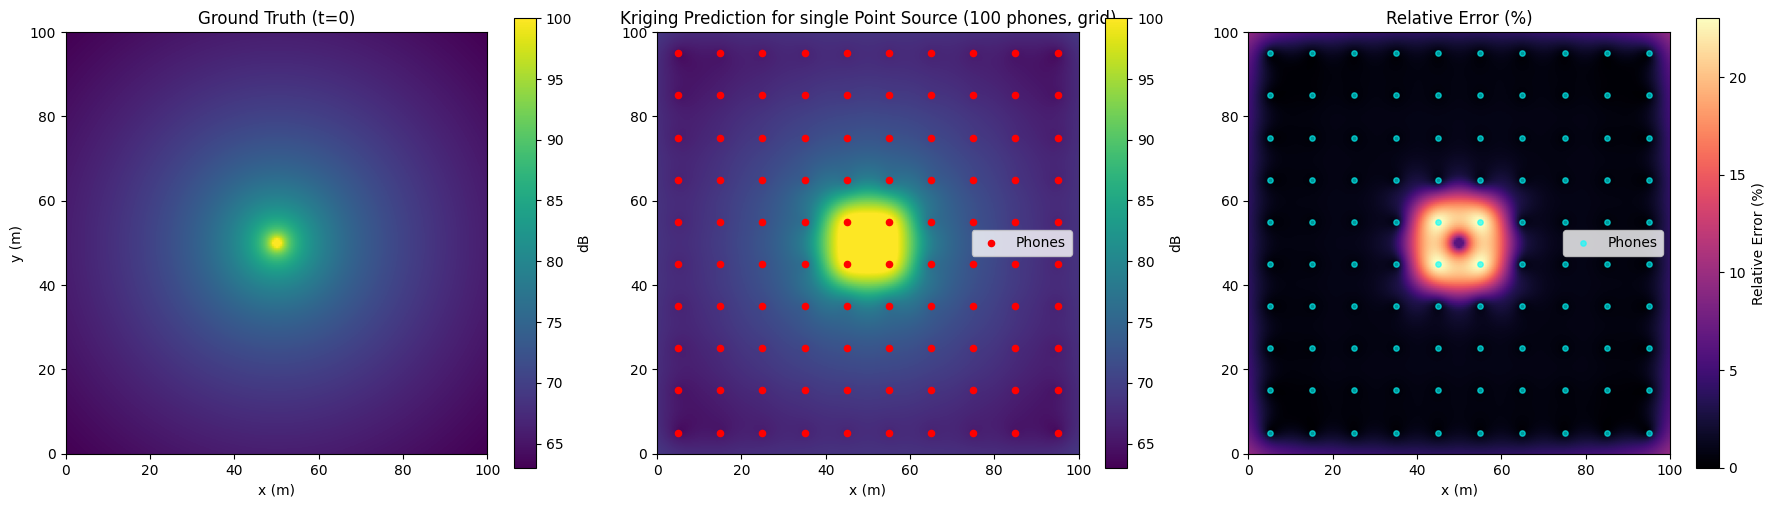

In [111]:
import point_source as sound_map

# 1. Load the sound maps and grid
sound_maps = sound_map.sound_maps
x = sound_map.x
y = sound_map.y

source_x = sound_map.source_x_positions
source_y = sound_map.source_y


# 2. Define phone configurations
phone_counts = [5, 10, 20, 50, 100]
layouts = ["random", "grid", "clustered"]


# 3. Prepare interpolation data (THIS WILL BE INPUT INTO THE INERPOLATION MODELS)
prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts
)


for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]

        # Ensure 2D inputs
        phone_levels = np.atleast_2d(data["phone_levels"])
        true_levels = np.atleast_2d(data["true_levels"])
        
        # Run interpolation
        predicted_levels = Kriging_Model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"],
        )

        # 1. Standard RMSE (Will be higher with a buffer)
        error = predicted_levels - true_levels
        audience_rmse = np.sqrt(np.mean(error ** 2))
        
        # 2. Safety Metrics (The buffer's true purpose)
        # Find only the pixels where we UNDERESTIMATED the true sound
        under_mask = error < 0 
        
        if np.any(under_mask):
            mean_under_db = np.abs(np.mean(error[under_mask]))
            max_under_db = np.abs(np.min(error)) # The most dangerous miss
        else:
            mean_under_db = 0.0
            max_under_db = 0.0

        results.append({
            "count": count, 
            "layout": layout, 
            "rmse": audience_rmse,
            "max_under_db": max_under_db
        })
        
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {audience_rmse:.2f} dB | Worst Under-Prediction: {max_under_db:.2f} dB")


N_phones = 100
layout_type = "grid"
# 3. Visualize a specific reconstruction (Time step 0 for 20 clustered phones)
target_config = prepared_data[(N_phones, layout_type)]
pred_map = Kriging_Model.fit_predict(
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Reshape the flat 1D query array (M,) back to 2D grid (len(y), len(x))
grid_shape = (len(y), len(x))
reconstructed_2d = pred_map[0].reshape(grid_shape)
ground_truth_2d = target_config["true_levels"][0].reshape(grid_shape)

# Compute Relative Error (%)
relative_error_2d = (np.abs(reconstructed_2d - ground_truth_2d) / np.abs(ground_truth_2d)) * 100

# Shared scale for Ground Truth and Prediction
vmin = ground_truth_2d.min()
vmax = ground_truth_2d.max()

#1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[0].set_title("Ground Truth (t=0)")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
plt.colorbar(im0, ax=axes[0], label="dB")

im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction for single Point Source ({N_phones} phones, {layout_type})")
axes[1].set_xlabel("x (m)")
axes[1].legend()
plt.colorbar(im1, ax=axes[1], label="dB")

im2 = axes[2].imshow(relative_error_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="magma", vmin=0)
axes[2].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="cyan", s=15, alpha=0.6, label="Phones")
axes[2].set_title("Relative Error (%)")
axes[2].set_xlabel("x (m)")
axes[2].legend()
plt.colorbar(im2, ax=axes[2], label="Relative Error (%)")


plt.tight_layout()
plt.show()


**3. Input the multiple point sources sound map to the Kriging Model**

3.1 Ordinary Kriging Model without additional Buffer

Phones:   5 | Layout: random     | RMSE: 4.94 dB | Worst Under-Prediction: 28.81 dB
Phones:   5 | Layout: grid       | RMSE: 5.59 dB | Worst Under-Prediction: 26.57 dB
Phones:   5 | Layout: clustered  | RMSE: 12.59 dB | Worst Under-Prediction: 16.32 dB
Phones:  10 | Layout: random     | RMSE: 5.94 dB | Worst Under-Prediction: 16.85 dB
Phones:  10 | Layout: grid       | RMSE: 6.58 dB | Worst Under-Prediction: 14.59 dB
Phones:  10 | Layout: clustered  | RMSE: 10.29 dB | Worst Under-Prediction: 16.41 dB
Phones:  20 | Layout: random     | RMSE: 5.21 dB | Worst Under-Prediction: 16.96 dB
Phones:  20 | Layout: grid       | RMSE: 4.15 dB | Worst Under-Prediction: 15.83 dB
Phones:  20 | Layout: clustered  | RMSE: 17.25 dB | Worst Under-Prediction: 215.68 dB
Phones:  50 | Layout: random     | RMSE: 4.00 dB | Worst Under-Prediction: 17.98 dB
Phones:  50 | Layout: grid       | RMSE: 47.51 dB | Worst Under-Prediction: 215.38 dB
Phones:  50 | Layout: clustered  | RMSE: 14.57 dB | Worst Under-Predic

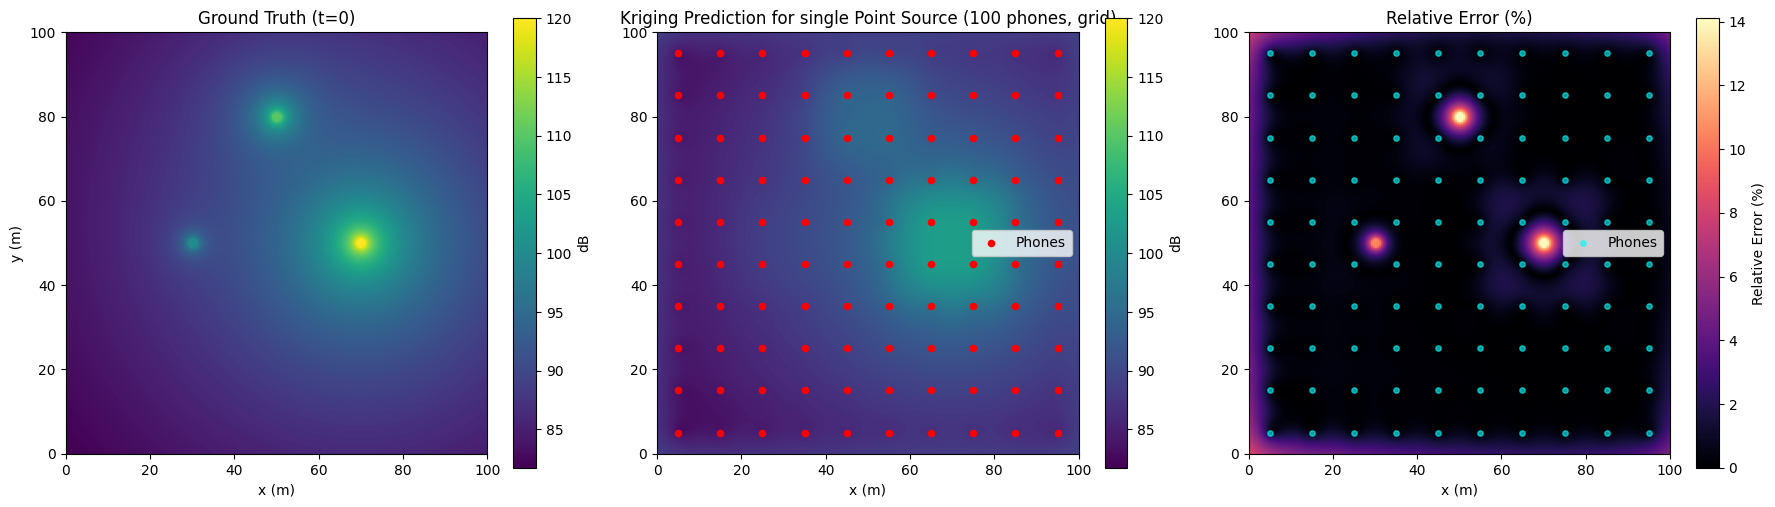

In [113]:
import multiple_point_sources as sound_map


# 1. Load the sound maps and grid
sound_maps = sound_map.sound_maps
x = sound_map.x
y = sound_map.y

source_x = sound_map.source_x_positions
source_y = sound_map.source_y


# 2. Define phone configurations
phone_counts = [5, 10, 20, 50, 100]
layouts = ["random", "grid", "clustered"]


# 3. Prepare interpolation data (THIS WILL BE INPUT INTO THE INERPOLATION MODELS)
prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts
)



# Track benchmarking results
results = []

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]

        # Ensure 2D inputs
        phone_levels = np.atleast_2d(data["phone_levels"])
        true_levels = np.atleast_2d(data["true_levels"])
        
        # Run interpolation
        predicted_levels = Kriging_Model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"],
        )

        # 1. Standard RMSE (Will be higher with a buffer)
        error = predicted_levels - true_levels
        audience_rmse = np.sqrt(np.mean(error ** 2))
        
        # 2. Safety Metrics (The buffer's true purpose)
        # Find only the pixels where we UNDERESTIMATED the true sound
        under_mask = error < 0 
        
        if np.any(under_mask):
            mean_under_db = np.abs(np.mean(error[under_mask]))
            max_under_db = np.abs(np.min(error)) # The most dangerous miss
        else:
            mean_under_db = 0.0
            max_under_db = 0.0

        results.append({
            "count": count, 
            "layout": layout, 
            "rmse": audience_rmse,
            "max_under_db": max_under_db
        })
        
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {audience_rmse:.2f} dB | Worst Under-Prediction: {max_under_db:.2f} dB")


N_phones = 100
layout_type = "grid"
# 3. Visualize a specific reconstruction (Time step 0 for 20 clustered phones)
target_config = prepared_data[(N_phones, layout_type)]
pred_map = ExactAcousticKriging.fit_predict(
    ExactAcousticKriging(),
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Reshape the flat 1D query array (M,) back to 2D grid (len(y), len(x))
grid_shape = (len(y), len(x))
reconstructed_2d = pred_map[0].reshape(grid_shape)
ground_truth_2d = target_config["true_levels"][0].reshape(grid_shape)

# Compute Relative Error (%)
relative_error_2d = (np.abs(reconstructed_2d - ground_truth_2d) / np.abs(ground_truth_2d)) * 100

# Shared scale for Ground Truth and Prediction
vmin = ground_truth_2d.min()
vmax = ground_truth_2d.max()

#1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[0].set_title("Ground Truth (t=0)")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
plt.colorbar(im0, ax=axes[0], label="dB")

im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction for single Point Source ({N_phones} phones, {layout_type})")
axes[1].set_xlabel("x (m)")
axes[1].legend()
plt.colorbar(im1, ax=axes[1], label="dB")

im2 = axes[2].imshow(relative_error_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="magma", vmin=0)
axes[2].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="cyan", s=15, alpha=0.6, label="Phones")
axes[2].set_title("Relative Error (%)")
axes[2].set_xlabel("x (m)")
axes[2].legend()
plt.colorbar(im2, ax=axes[2], label="Relative Error (%)")


plt.tight_layout()
plt.show()

3.2 Ordinary Kriging Model with additional Buffer

Phones:   5 | Layout: random     | RMSE: 4.94 dB | Worst Under-Prediction: 28.81 dB
Phones:   5 | Layout: grid       | RMSE: 5.59 dB | Worst Under-Prediction: 26.57 dB
Phones:   5 | Layout: clustered  | RMSE: 12.59 dB | Worst Under-Prediction: 16.32 dB
Phones:  10 | Layout: random     | RMSE: 5.94 dB | Worst Under-Prediction: 16.85 dB
Phones:  10 | Layout: grid       | RMSE: 6.58 dB | Worst Under-Prediction: 14.59 dB
Phones:  10 | Layout: clustered  | RMSE: 10.29 dB | Worst Under-Prediction: 16.41 dB
Phones:  20 | Layout: random     | RMSE: 5.21 dB | Worst Under-Prediction: 16.96 dB
Phones:  20 | Layout: grid       | RMSE: 4.15 dB | Worst Under-Prediction: 15.83 dB
Phones:  20 | Layout: clustered  | RMSE: 17.25 dB | Worst Under-Prediction: 215.68 dB
Phones:  50 | Layout: random     | RMSE: 4.00 dB | Worst Under-Prediction: 17.98 dB
Phones:  50 | Layout: grid       | RMSE: 47.51 dB | Worst Under-Prediction: 215.38 dB
Phones:  50 | Layout: clustered  | RMSE: 14.57 dB | Worst Under-Predic

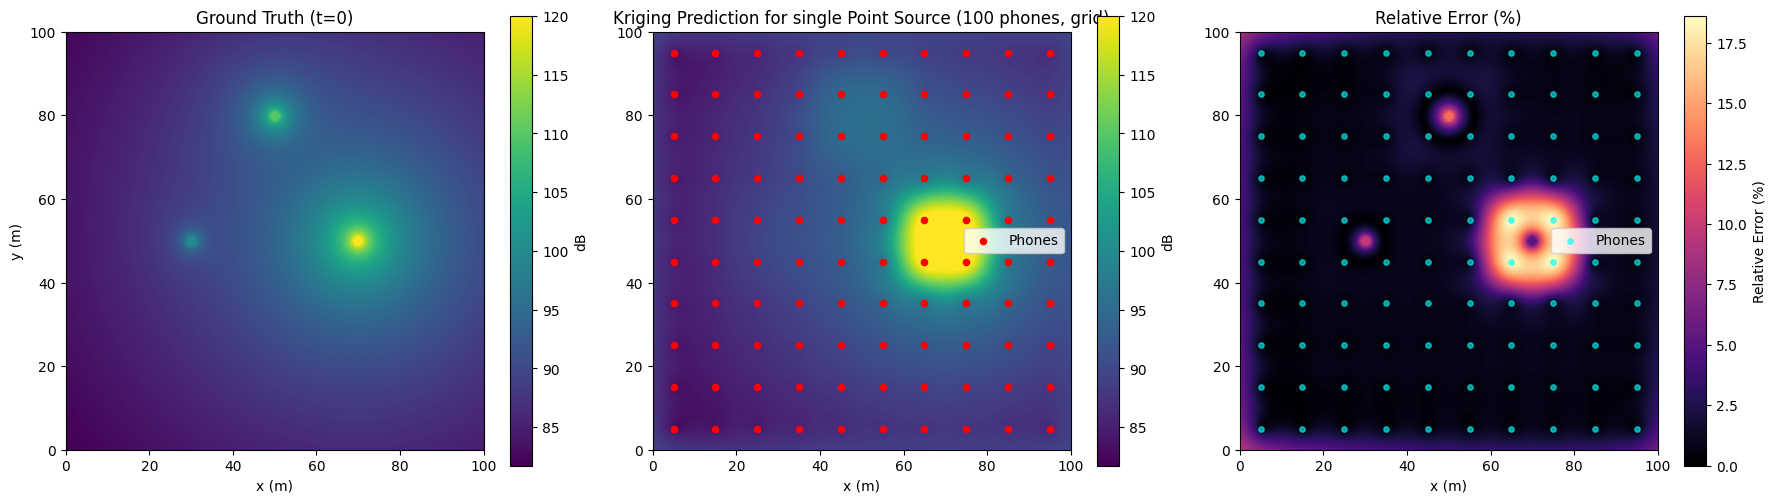

In [114]:
import multiple_point_sources as sound_map


# 1. Load the sound maps and grid
sound_maps = sound_map.sound_maps
x = sound_map.x
y = sound_map.y

source_x = sound_map.source_x_positions
source_y = sound_map.source_y


# 2. Define phone configurations
phone_counts = [5, 10, 20, 50, 100]
layouts = ["random", "grid", "clustered"]


# 3. Prepare interpolation data (THIS WILL BE INPUT INTO THE INERPOLATION MODELS)
prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts
)



# Track benchmarking results
results = []

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]

        # Ensure 2D inputs
        phone_levels = np.atleast_2d(data["phone_levels"])
        true_levels = np.atleast_2d(data["true_levels"])
        
        # Run interpolation
        predicted_levels = Kriging_Model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"],
        )

        # 1. Standard RMSE (Will be higher with a buffer)
        error = predicted_levels - true_levels
        audience_rmse = np.sqrt(np.mean(error ** 2))
        
        # 2. Safety Metrics (The buffer's true purpose)
        # Find only the pixels where we UNDERESTIMATED the true sound
        under_mask = error < 0 
        
        if np.any(under_mask):
            mean_under_db = np.abs(np.mean(error[under_mask]))
            max_under_db = np.abs(np.min(error)) # The most dangerous miss
        else:
            mean_under_db = 0.0
            max_under_db = 0.0

        results.append({
            "count": count, 
            "layout": layout, 
            "rmse": audience_rmse,
            "max_under_db": max_under_db
        })
        
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {audience_rmse:.2f} dB | Worst Under-Prediction: {max_under_db:.2f} dB")


N_phones = 100
layout_type = "grid"
# 3. Visualize a specific reconstruction (Time step 0 for 20 clustered phones)
target_config = prepared_data[(N_phones, layout_type)]
pred_map = Kriging_Model.fit_predict(
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Reshape the flat 1D query array (M,) back to 2D grid (len(y), len(x))
grid_shape = (len(y), len(x))
reconstructed_2d = pred_map[0].reshape(grid_shape)
ground_truth_2d = target_config["true_levels"][0].reshape(grid_shape)

# Compute Relative Error (%)
relative_error_2d = (np.abs(reconstructed_2d - ground_truth_2d) / np.abs(ground_truth_2d)) * 100

# Shared scale for Ground Truth and Prediction
vmin = ground_truth_2d.min()
vmax = ground_truth_2d.max()

#1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[0].set_title("Ground Truth (t=0)")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
plt.colorbar(im0, ax=axes[0], label="dB")

im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction for single Point Source ({N_phones} phones, {layout_type})")
axes[1].set_xlabel("x (m)")
axes[1].legend()
plt.colorbar(im1, ax=axes[1], label="dB")

im2 = axes[2].imshow(relative_error_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="magma", vmin=0)
axes[2].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="cyan", s=15, alpha=0.6, label="Phones")
axes[2].set_title("Relative Error (%)")
axes[2].set_xlabel("x (m)")
axes[2].legend()
plt.colorbar(im2, ax=axes[2], label="Relative Error (%)")


plt.tight_layout()
plt.show()

4. Input the single moving point source sound map to the Kriging Model

4.1 Ordinary Kriging Model without additional Buffer

Phones:   5 | Layout: random     | RMSE: 6.23 dB | Worst Under-Prediction: 33.89 dB
Phones:   5 | Layout: grid       | RMSE: 7.93 dB | Worst Under-Prediction: 31.88 dB
Phones:   5 | Layout: clustered  | RMSE: 5.85 dB | Worst Under-Prediction: 37.93 dB
Phones:  10 | Layout: random     | RMSE: 5.41 dB | Worst Under-Prediction: 34.23 dB
Phones:  10 | Layout: grid       | RMSE: 10.14 dB | Worst Under-Prediction: 30.87 dB
Phones:  10 | Layout: clustered  | RMSE: 5.94 dB | Worst Under-Prediction: 37.34 dB
Phones:  20 | Layout: random     | RMSE: 5.73 dB | Worst Under-Prediction: 26.38 dB
Phones:  20 | Layout: grid       | RMSE: 7.73 dB | Worst Under-Prediction: 18.58 dB
Phones:  20 | Layout: clustered  | RMSE: 5.93 dB | Worst Under-Prediction: 37.36 dB
Phones:  50 | Layout: random     | RMSE: 17.80 dB | Worst Under-Prediction: 203.72 dB
Phones:  50 | Layout: grid       | RMSE: 12.11 dB | Worst Under-Prediction: 195.23 dB
Phones:  50 | Layout: clustered  | RMSE: 5.53 dB | Worst Under-Predicti

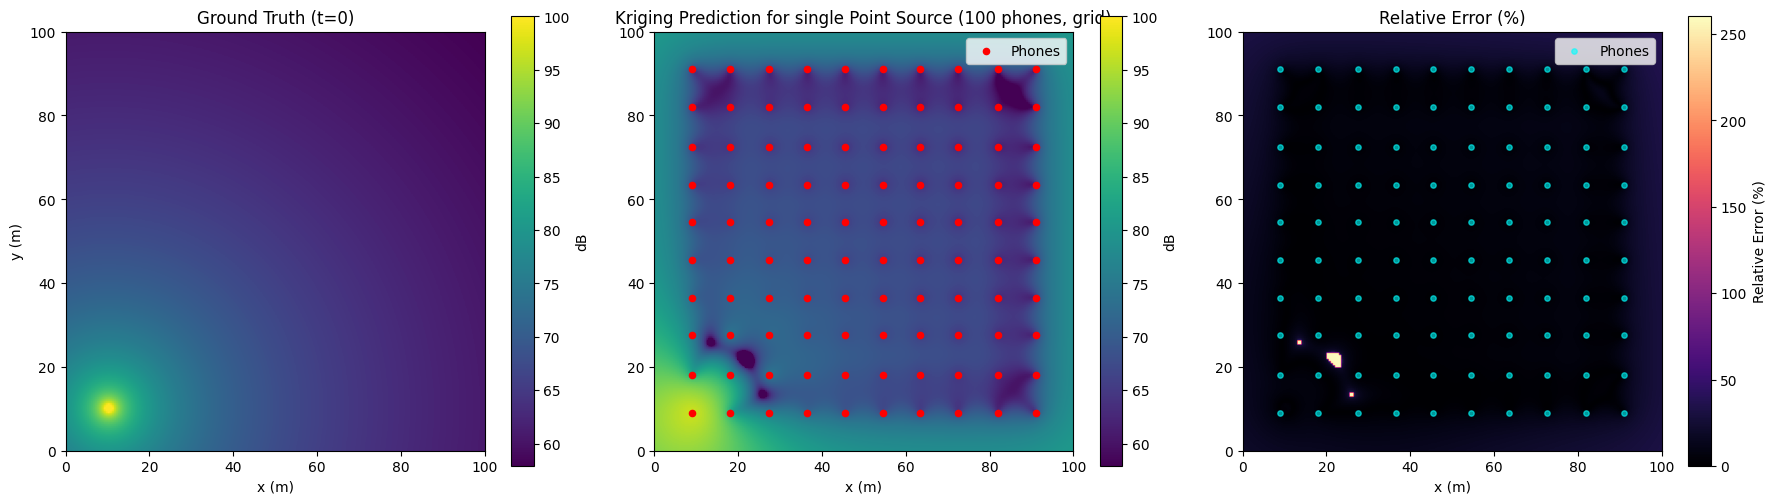

In [115]:
import single_moving_point_source as sound_map
from extract_sound_venues import prepare_interpolation_data


# 1. Load the sound maps and grid
sound_maps = sound_map.sound_maps
x = sound_map.x
y = sound_map.y

source_x = sound_map.source_x_positions
source_y = sound_map.source_y


# 2. Define phone configurations
phone_counts = [5, 10, 20, 50, 100]
layouts = ["random", "grid", "clustered"]


# 3. Prepare interpolation data (THIS WILL BE INPUT INTO THE INERPOLATION MODELS)
prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts
)



# Track benchmarking results
results = []

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]

        # Ensure 2D inputs
        phone_levels = np.atleast_2d(data["phone_levels"])
        true_levels = np.atleast_2d(data["true_levels"])
        
        # Run interpolation
        predicted_levels = Kriging_Model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"],
        )

        # 1. Standard RMSE (Will be higher with a buffer)
        error = predicted_levels - true_levels
        audience_rmse = np.sqrt(np.mean(error ** 2))
        
        # 2. Safety Metrics (The buffer's true purpose)
        # Find only the pixels where we UNDERESTIMATED the true sound
        under_mask = error < 0 
        
        if np.any(under_mask):
            mean_under_db = np.abs(np.mean(error[under_mask]))
            max_under_db = np.abs(np.min(error)) # The most dangerous miss
        else:
            mean_under_db = 0.0
            max_under_db = 0.0

        results.append({
            "count": count, 
            "layout": layout, 
            "rmse": audience_rmse,
            "max_under_db": max_under_db
        })
        
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {audience_rmse:.2f} dB | Worst Under-Prediction: {max_under_db:.2f} dB")


N_phones = 100
layout_type = "grid"
# 3. Visualize a specific reconstruction (Time step 0 for 20 clustered phones)
target_config = prepared_data[(N_phones, layout_type)]
pred_map = ExactAcousticKriging.fit_predict(ExactAcousticKriging(),
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Reshape the flat 1D query array (M,) back to 2D grid (len(y), len(x))
grid_shape = (len(y), len(x))
reconstructed_2d = pred_map[0].reshape(grid_shape)
ground_truth_2d = target_config["true_levels"][0].reshape(grid_shape)

# Compute Relative Error (%)
relative_error_2d = (np.abs(reconstructed_2d - ground_truth_2d) / np.abs(ground_truth_2d)) * 100

# Shared scale for Ground Truth and Prediction
vmin = ground_truth_2d.min()
vmax = ground_truth_2d.max()

#1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[0].set_title("Ground Truth (t=0)")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
plt.colorbar(im0, ax=axes[0], label="dB")

im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction for single Point Source ({N_phones} phones, {layout_type})")
axes[1].set_xlabel("x (m)")
axes[1].legend()
plt.colorbar(im1, ax=axes[1], label="dB")

im2 = axes[2].imshow(relative_error_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="magma", vmin=0)
axes[2].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="cyan", s=15, alpha=0.6, label="Phones")
axes[2].set_title("Relative Error (%)")
axes[2].set_xlabel("x (m)")
axes[2].legend()
plt.colorbar(im2, ax=axes[2], label="Relative Error (%)")


plt.tight_layout()
plt.show()

4.2 Ordinary Kriging Model with additional Buffer

Phones:  10 | Layout: random     | RMSE: 5.39 dB | Worst Under-Prediction: 34.93 dB
Phones:  10 | Layout: grid       | RMSE: 7.22 dB | Worst Under-Prediction: 34.99 dB
Phones:  10 | Layout: clustered  | RMSE: 7.70 dB | Worst Under-Prediction: 36.44 dB
Phones:  30 | Layout: random     | RMSE: 8.99 dB | Worst Under-Prediction: 197.45 dB
Phones:  30 | Layout: grid       | RMSE: 5.53 dB | Worst Under-Prediction: 16.73 dB
Phones:  30 | Layout: clustered  | RMSE: 7.20 dB | Worst Under-Prediction: 37.18 dB
Phones:  50 | Layout: random     | RMSE: 15.83 dB | Worst Under-Prediction: 199.91 dB
Phones:  50 | Layout: grid       | RMSE: 5.20 dB | Worst Under-Prediction: 194.13 dB
Phones:  50 | Layout: clustered  | RMSE: 6.02 dB | Worst Under-Prediction: 36.53 dB
Phones: 100 | Layout: random     | RMSE: 14.90 dB | Worst Under-Prediction: 201.96 dB
Phones: 100 | Layout: grid       | RMSE: 24.14 dB | Worst Under-Prediction: 198.94 dB
Phones: 100 | Layout: clustered  | RMSE: 7.41 dB | Worst Under-Predi

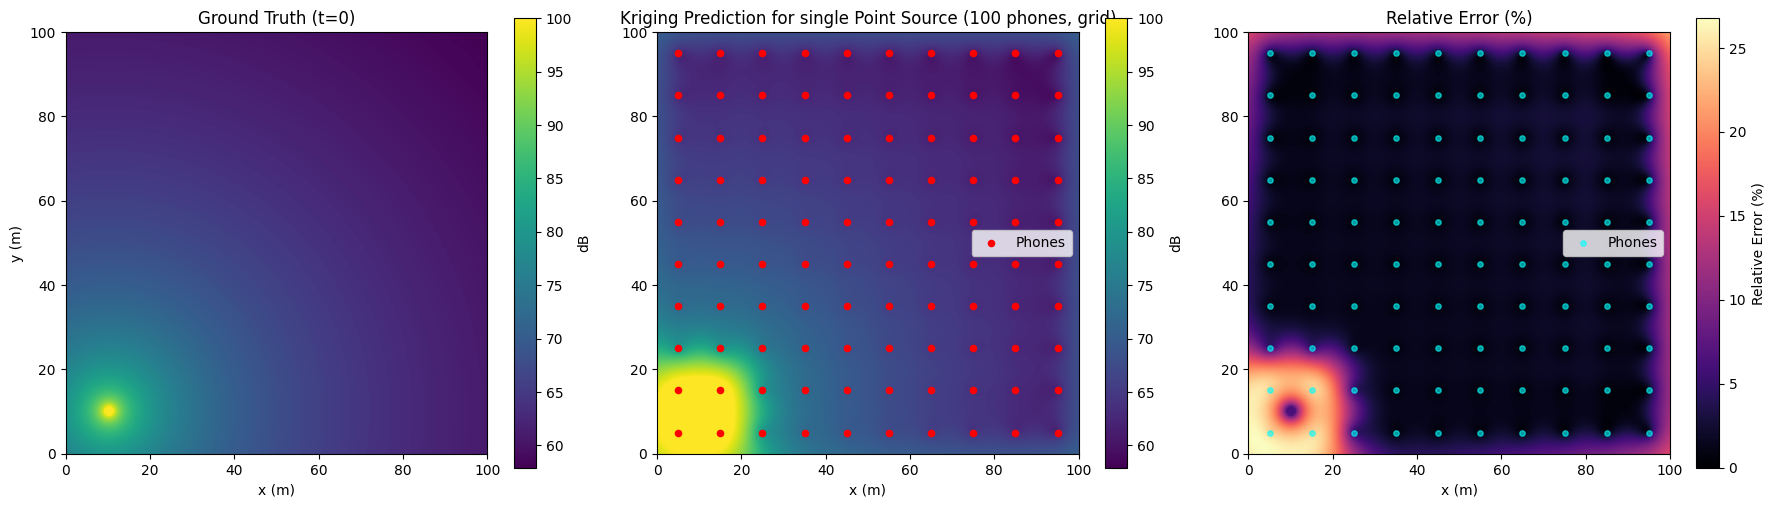

In [118]:
#1. Load the simulated sound map and audience area
import single_moving_point_source as sound_map
#import Basic_Sound_Map_Files.single_moving_point_source as sound_map
from Basic_Sound_Map_Files.extract_sound import prepare_interpolation_data


# 1. Load the sound maps and grid
sound_maps = sound_map.sound_maps
x = sound_map.x
y = sound_map.y

source_x = sound_map.source_x_positions
source_y = sound_map.source_y


grid_shape = (len(y), len(x))

#2. Define phone configurations
phone_counts = [10, 30, 50, 100, 250]
layouts = ["random", "grid", "clustered"]

#3. generate phone positions and extract their sound measurements
prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts,
    seed=42)


#4. Define phone configurations
phone_counts = [10, 30, 50, 100, 250]
layouts = ["random", "grid", "clustered"]

#5. Track benchmarking results
results = []

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]

        # Ensure 2D inputs
        phone_levels = np.atleast_2d(data["phone_levels"])
        true_levels = np.atleast_2d(data["true_levels"])
        
        # Run interpolation
        predicted_levels = Kriging_Model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"],
        )

        # 1. Standard RMSE (Will be higher with a buffer)
        error = predicted_levels - true_levels
        audience_rmse = np.sqrt(np.mean(error ** 2))
        
        # 2. Safety Metrics (The buffer's true purpose)
        # Find only the pixels where we UNDERESTIMATED the true sound
        under_mask = error < 0 
        
        if np.any(under_mask):
            mean_under_db = np.abs(np.mean(error[under_mask]))
            max_under_db = np.abs(np.min(error)) # The most dangerous miss
        else:
            mean_under_db = 0.0
            max_under_db = 0.0

        results.append({
            "count": count, 
            "layout": layout, 
            "rmse": audience_rmse,
            "max_under_db": max_under_db
        })
        
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {audience_rmse:.2f} dB | Worst Under-Prediction: {max_under_db:.2f} dB")

N_phones = 100
layout_type = "grid"
# 3. Visualize a specific reconstruction (Time step 0 for 20 clustered phones)
target_config = prepared_data[(N_phones, layout_type)]
pred_map = Kriging_Model.fit_predict(
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Reshape the flat 1D query array (M,) back to 2D grid (len(y), len(x))
grid_shape = (len(y), len(x))
reconstructed_2d = pred_map[0].reshape(grid_shape)
ground_truth_2d = target_config["true_levels"][0].reshape(grid_shape)

# Compute Relative Error (%)
relative_error_2d = (np.abs(reconstructed_2d - ground_truth_2d) / np.abs(ground_truth_2d)) * 100

# Shared scale for Ground Truth and Prediction
vmin = ground_truth_2d.min()
vmax = ground_truth_2d.max()

#1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[0].set_title("Ground Truth (t=0)")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
plt.colorbar(im0, ax=axes[0], label="dB")

im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction for single Point Source ({N_phones} phones, {layout_type})")
axes[1].set_xlabel("x (m)")
axes[1].legend()
plt.colorbar(im1, ax=axes[1], label="dB")

im2 = axes[2].imshow(relative_error_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="magma", vmin=0)
axes[2].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="cyan", s=15, alpha=0.6, label="Phones")
axes[2].set_title("Relative Error (%)")
axes[2].set_xlabel("x (m)")
axes[2].legend()
plt.colorbar(im2, ax=axes[2], label="Relative Error (%)")


plt.tight_layout()
plt.show()

5. O2 Music Venue

5.1 Ordinary Kriging Model without additional Buffer

Phones:  10 | Layout: random     | RMSE: 2.69 dB | Worst Under-Prediction: 12.22 dB
Phones:  10 | Layout: grid       | RMSE: 2.57 dB | Worst Under-Prediction: 11.73 dB
Phones:  10 | Layout: clustered  | RMSE: 8.09 dB | Worst Under-Prediction: 6.84 dB
Phones:  30 | Layout: random     | RMSE: 2.09 dB | Worst Under-Prediction: 12.11 dB
Phones:  30 | Layout: grid       | RMSE: 2.56 dB | Worst Under-Prediction: 1.39 dB
Phones:  30 | Layout: clustered  | RMSE: 7.74 dB | Worst Under-Prediction: 7.31 dB
Phones:  50 | Layout: random     | RMSE: 1.64 dB | Worst Under-Prediction: 11.38 dB
Phones:  50 | Layout: grid       | RMSE: 1.51 dB | Worst Under-Prediction: 1.14 dB
Phones:  50 | Layout: clustered  | RMSE: 5.81 dB | Worst Under-Prediction: 8.81 dB
Phones: 100 | Layout: random     | RMSE: 1.21 dB | Worst Under-Prediction: 9.33 dB
Phones: 100 | Layout: grid       | RMSE: 0.85 dB | Worst Under-Prediction: 1.29 dB
Phones: 100 | Layout: clustered  | RMSE: 5.44 dB | Worst Under-Prediction: 9.06 dB


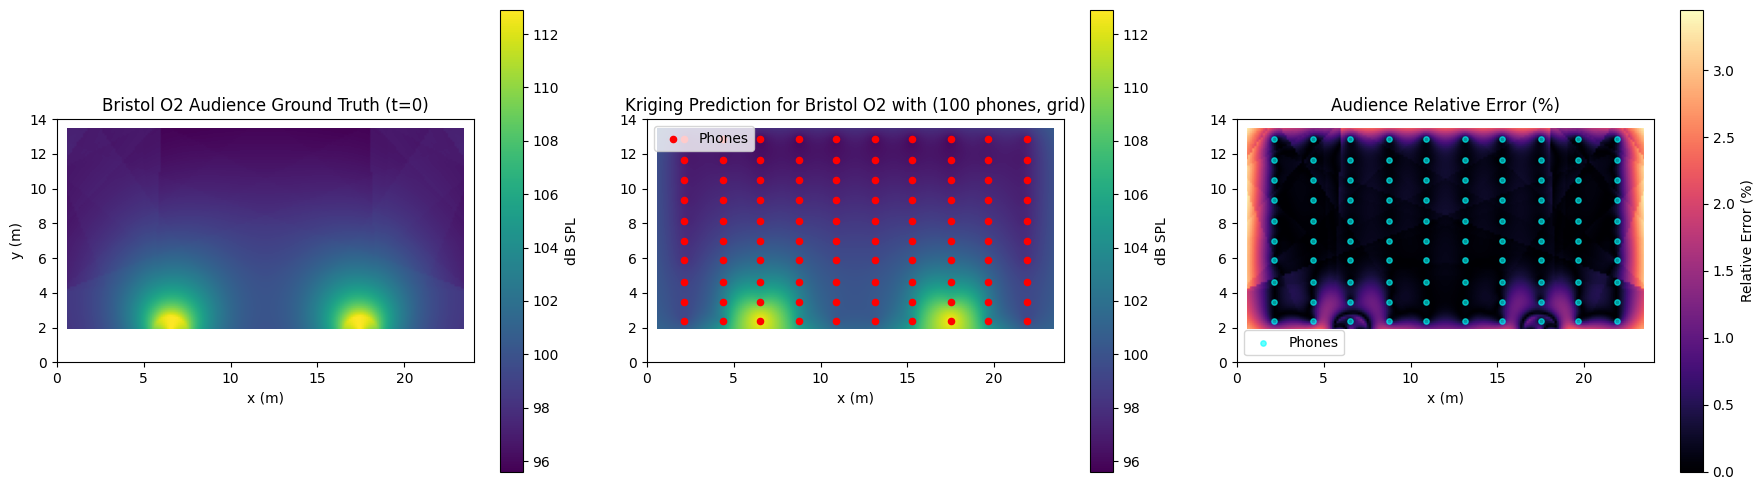

In [121]:
#1. Load the simulated sound map and audience area
import Working_final_maps.concert_map as sound_map
from Working_final_maps.extract_sound_venues import prepare_interpolation_data

sound_maps, x, y, allowed_mask = sound_map.load_sound_map()
#Dynamically calculate the grid shape based on the loaded map
grid_shape = (len(y), len(x))

#2. Define phone configurations
phone_counts = [10, 30, 50, 100, 250]
layouts = ["random", "grid", "clustered"]

#3. generate phone positions and extract their sound measurements
prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts,
    seed=42,
    allowed_mask=allowed_mask)


#4. Define phone configurations
phone_counts = [10, 30, 50, 100, 250]
layouts = ["random", "grid", "clustered"]

#5. Track benchmarking results
results = []

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]

        # Ensure 2D inputs
        phone_levels = np.atleast_2d(data["phone_levels"])
        true_levels = np.atleast_2d(data["true_levels"])
        
        # Run interpolation
        predicted_levels = no_buffer_Kriging_Model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"],
        )

        # 1. Standard RMSE (Will be higher with a buffer)
        error = predicted_levels - true_levels
        audience_rmse = np.sqrt(np.mean(error ** 2))
        
        # 2. Safety Metrics (The buffer's true purpose)
        # Find only the pixels where we UNDERESTIMATED the true sound
        under_mask = error < 0 
        
        if np.any(under_mask):
            mean_under_db = np.abs(np.mean(error[under_mask]))
            max_under_db = np.abs(np.min(error)) # The most dangerous miss
        else:
            mean_under_db = 0.0
            max_under_db = 0.0

        results.append({
            "count": count, 
            "layout": layout, 
            "rmse": audience_rmse,
            "max_under_db": max_under_db
        })
        
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {audience_rmse:.2f} dB | Worst Under-Prediction: {max_under_db:.2f} dB")


N_phones = 100
layout_type = "grid"

# 6. Visualize a specific reconstruction (Time step 0 for 20 clustered phones)
target_config = prepared_data[(N_phones, layout_type)]
target_phone_levels = np.atleast_2d(target_config["phone_levels"])
target_true_levels = np.atleast_2d(target_config["true_levels"])
mask_2d = np.asarray(target_config["allowed_mask"]).reshape(grid_shape)

pred_map = ExactAcousticKriging.fit_predict(ExactAcousticKriging(),
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Unpack audience points back into full (len(y), len(x)) grids
ground_truth_2d = np.full(grid_shape, np.nan)
reconstructed_2d = np.full(grid_shape, np.nan)

ground_truth_2d[mask_2d] = target_true_levels[0]
reconstructed_2d[mask_2d] = pred_map[0]

# Compute Relative Error (%)
relative_error_2d = (np.abs(reconstructed_2d - ground_truth_2d) / np.abs(ground_truth_2d)) * 100

# nanmin/nanmax ensure NaNs outside the audience don't corrupt color limits
vmin = np.nanmin(ground_truth_2d)
vmax = np.nanmax(ground_truth_2d)

#Plot figures
#1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax, cmap="viridis")
axes[0].set_title("Bristol O2 Audience Ground Truth (t=0)")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
plt.colorbar(im0, ax=axes[0], label="dB SPL")

im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax, cmap="viridis")
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction for Bristol O2 with ({N_phones} phones, {layout_type})")
axes[1].set_xlabel("x (m)")
axes[1].legend(loc="upper left")
plt.colorbar(im1, ax=axes[1], label="dB SPL")

im2 = axes[2].imshow(relative_error_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="magma", vmin=0)
axes[2].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="cyan", s=15, alpha=0.6, label="Phones")
axes[2].set_title("Audience Relative Error (%)")
axes[2].set_xlabel("x (m)")
axes[2].legend()
plt.colorbar(im2, ax=axes[2], label="Relative Error (%)")


plt.tight_layout()
plt.show()

5.2 Ordinary Kriging Model with additional Buffer

Phones:  10 | Layout: random     | RMSE: 3.04 dB | Worst Under-Prediction: 10.85 dB
Phones:  10 | Layout: grid       | RMSE: 2.97 dB | Worst Under-Prediction: 10.14 dB
Phones:  10 | Layout: clustered  | RMSE: 10.92 dB | Worst Under-Prediction: 4.24 dB
Phones:  30 | Layout: random     | RMSE: 2.33 dB | Worst Under-Prediction: 9.75 dB
Phones:  30 | Layout: grid       | RMSE: 3.93 dB | Worst Under-Prediction: 0.00 dB
Phones:  30 | Layout: clustered  | RMSE: 10.48 dB | Worst Under-Prediction: 4.69 dB
Phones:  50 | Layout: random     | RMSE: 1.88 dB | Worst Under-Prediction: 9.32 dB
Phones:  50 | Layout: grid       | RMSE: 2.49 dB | Worst Under-Prediction: 0.00 dB
Phones:  50 | Layout: clustered  | RMSE: 7.76 dB | Worst Under-Prediction: 6.69 dB
Phones: 100 | Layout: random     | RMSE: 1.64 dB | Worst Under-Prediction: 5.27 dB
Phones: 100 | Layout: grid       | RMSE: 1.66 dB | Worst Under-Prediction: 0.04 dB
Phones: 100 | Layout: clustered  | RMSE: 7.50 dB | Worst Under-Prediction: 6.67 dB


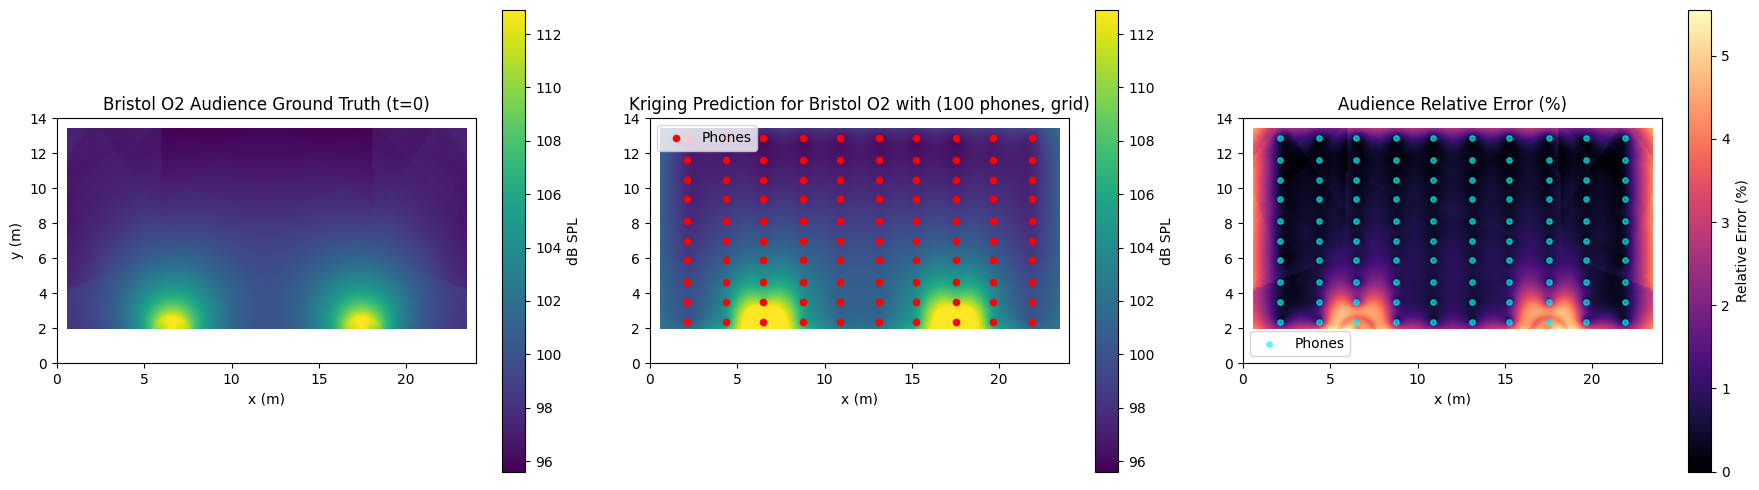

In [119]:
#1. Load the simulated sound map and audience area
import Working_final_maps.concert_map as sound_map
from Working_final_maps.extract_sound_venues import prepare_interpolation_data

sound_maps, x, y, allowed_mask = sound_map.load_sound_map()
#Dynamically calculate the grid shape based on the loaded map
grid_shape = (len(y), len(x))

#2. Define phone configurations
phone_counts = [10, 30, 50, 100, 250]
layouts = ["random", "grid", "clustered"]

#3. generate phone positions and extract their sound measurements
prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts,
    seed=42,
    allowed_mask=allowed_mask)


#4. Define phone configurations
phone_counts = [10, 30, 50, 100, 250]
layouts = ["random", "grid", "clustered"]

#5. Track benchmarking results
results = []

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]

        # Ensure 2D inputs
        phone_levels = np.atleast_2d(data["phone_levels"])
        true_levels = np.atleast_2d(data["true_levels"])
        
        # Run interpolation
        predicted_levels = Kriging_Model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"],
        )

        # 1. Standard RMSE (Will be higher with a buffer)
        error = predicted_levels - true_levels
        audience_rmse = np.sqrt(np.mean(error ** 2))
        
        # 2. Safety Metrics (The buffer's true purpose)
        # Find only the pixels where we UNDERESTIMATED the true sound
        under_mask = error < 0 
        
        if np.any(under_mask):
            mean_under_db = np.abs(np.mean(error[under_mask]))
            max_under_db = np.abs(np.min(error)) # The most dangerous miss
        else:
            mean_under_db = 0.0
            max_under_db = 0.0

        results.append({
            "count": count, 
            "layout": layout, 
            "rmse": audience_rmse,
            "max_under_db": max_under_db
        })
        
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {audience_rmse:.2f} dB | Worst Under-Prediction: {max_under_db:.2f} dB")


N_phones = 100
layout_type = "grid"

# 6. Visualize a specific reconstruction (Time step 0 for 20 clustered phones)
target_config = prepared_data[(N_phones, layout_type)]
target_phone_levels = np.atleast_2d(target_config["phone_levels"])
target_true_levels = np.atleast_2d(target_config["true_levels"])
mask_2d = np.asarray(target_config["allowed_mask"]).reshape(grid_shape)

pred_map = Kriging_Model.fit_predict(
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Unpack audience points back into full (len(y), len(x)) grids
ground_truth_2d = np.full(grid_shape, np.nan)
reconstructed_2d = np.full(grid_shape, np.nan)

ground_truth_2d[mask_2d] = target_true_levels[0]
reconstructed_2d[mask_2d] = pred_map[0]

# Compute Relative Error (%)
relative_error_2d = (np.abs(reconstructed_2d - ground_truth_2d) / np.abs(ground_truth_2d)) * 100

# nanmin/nanmax ensure NaNs outside the audience don't corrupt color limits
vmin = np.nanmin(ground_truth_2d)
vmax = np.nanmax(ground_truth_2d)

#Plot figures
#1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax, cmap="viridis")
axes[0].set_title("Bristol O2 Audience Ground Truth (t=0)")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
plt.colorbar(im0, ax=axes[0], label="dB SPL")

im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax, cmap="viridis")
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction for Bristol O2 with ({N_phones} phones, {layout_type})")
axes[1].set_xlabel("x (m)")
axes[1].legend(loc="upper left")
plt.colorbar(im1, ax=axes[1], label="dB SPL")

im2 = axes[2].imshow(relative_error_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="magma", vmin=0)
axes[2].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="cyan", s=15, alpha=0.6, label="Phones")
axes[2].set_title("Audience Relative Error (%)")
axes[2].set_xlabel("x (m)")
axes[2].legend()
plt.colorbar(im2, ax=axes[2], label="Relative Error (%)")


plt.tight_layout()
plt.show()

Phones:  10 | Layout: random     | RMSE: 6.74 dB | Worst Under-Prediction: 6.32 dB
Phones:  10 | Layout: grid       | RMSE: 6.83 dB | Worst Under-Prediction: 5.77 dB
Phones:  10 | Layout: clustered  | RMSE: 13.78 dB | Worst Under-Prediction: 0.80 dB
Phones:  30 | Layout: random     | RMSE: 5.41 dB | Worst Under-Prediction: 5.87 dB
Phones:  30 | Layout: grid       | RMSE: 7.16 dB | Worst Under-Prediction: 0.00 dB
Phones:  30 | Layout: clustered  | RMSE: 13.16 dB | Worst Under-Prediction: 1.31 dB
Phones:  50 | Layout: random     | RMSE: 4.79 dB | Worst Under-Prediction: 5.69 dB
Phones:  50 | Layout: grid       | RMSE: 5.46 dB | Worst Under-Prediction: 0.00 dB
Phones:  50 | Layout: clustered  | RMSE: 11.04 dB | Worst Under-Prediction: 2.98 dB
Phones: 100 | Layout: random     | RMSE: 4.12 dB | Worst Under-Prediction: 3.28 dB
Phones: 100 | Layout: grid       | RMSE: 4.24 dB | Worst Under-Prediction: 0.00 dB
Phones: 100 | Layout: clustered  | RMSE: 10.57 dB | Worst Under-Prediction: 3.37 dB


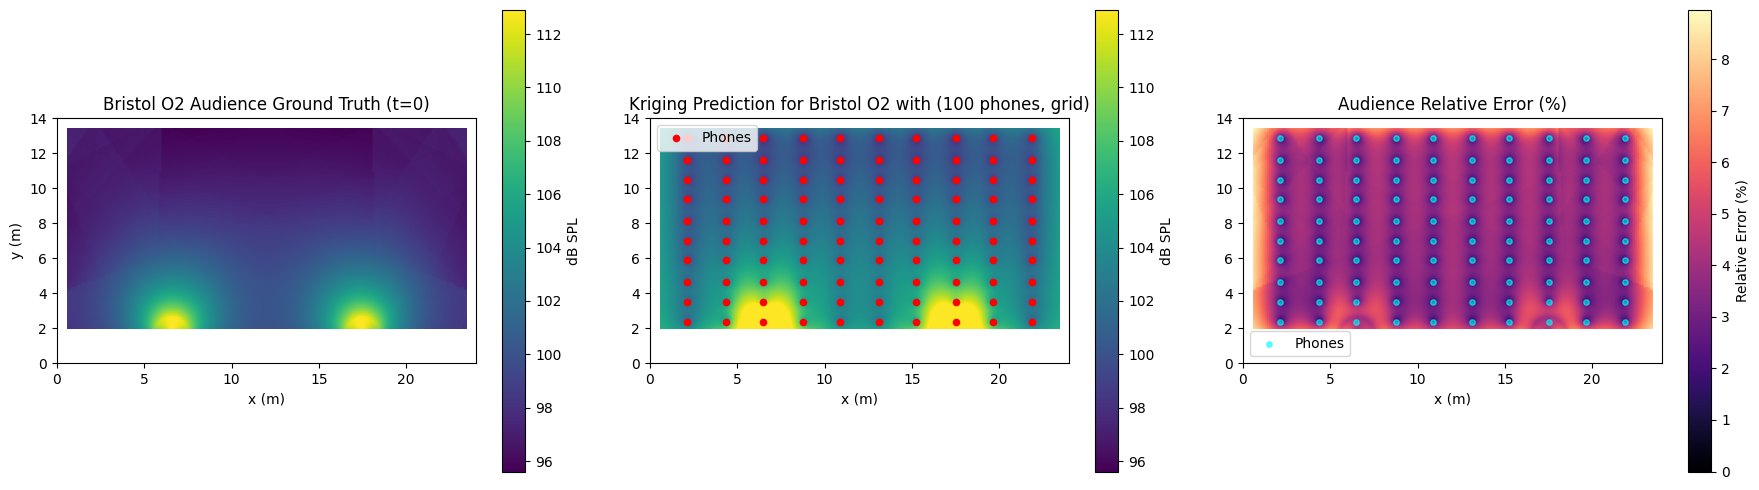

In [80]:
#1. Load the simulated sound map and audience area
import Working_final_maps.concert_map as sound_map
from Working_final_maps.extract_sound_venues import prepare_interpolation_data

sound_maps, x, y, allowed_mask = sound_map.load_sound_map()
#Dynamically calculate the grid shape based on the loaded map
grid_shape = (len(y), len(x))

#2. Define phone configurations
phone_counts = [10, 30, 50, 100, 250]
layouts = ["random", "grid", "clustered"]

#3. generate phone positions and extract their sound measurements
prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts,
    seed=42,
    allowed_mask=allowed_mask)


#4. Define phone configurations
phone_counts = [10, 30, 50, 100, 250]
layouts = ["random", "grid", "clustered"]

#5. Track benchmarking results
results = []

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]

        # Ensure 2D inputs
        phone_levels = np.atleast_2d(data["phone_levels"])
        true_levels = np.atleast_2d(data["true_levels"])
        
        # Run interpolation
        predicted_levels = Kriging_Model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"],
        )

        # 1. Standard RMSE (Will be higher with a buffer)
        error = predicted_levels - true_levels
        audience_rmse = np.sqrt(np.mean(error ** 2))
        
        # 2. Safety Metrics (The buffer's true purpose)
        # Find only the pixels where we UNDERESTIMATED the true sound
        under_mask = error < 0 
        
        if np.any(under_mask):
            mean_under_db = np.abs(np.mean(error[under_mask]))
            max_under_db = np.abs(np.min(error)) # The most dangerous miss
        else:
            mean_under_db = 0.0
            max_under_db = 0.0

        results.append({
            "count": count, 
            "layout": layout, 
            "rmse": audience_rmse,
            "max_under_db": max_under_db
        })
        
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {audience_rmse:.2f} dB | Worst Under-Prediction: {max_under_db:.2f} dB")


N_phones = 100
layout_type = "grid"

# 6. Visualize a specific reconstruction (Time step 0 for 20 clustered phones)
target_config = prepared_data[(N_phones, layout_type)]
target_phone_levels = np.atleast_2d(target_config["phone_levels"])
target_true_levels = np.atleast_2d(target_config["true_levels"])
mask_2d = np.asarray(target_config["allowed_mask"]).reshape(grid_shape)

pred_map = Kriging_Model.fit_predict(
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Unpack audience points back into full (len(y), len(x)) grids
ground_truth_2d = np.full(grid_shape, np.nan)
reconstructed_2d = np.full(grid_shape, np.nan)

ground_truth_2d[mask_2d] = target_true_levels[0]
reconstructed_2d[mask_2d] = pred_map[0]

# Compute Relative Error (%)
relative_error_2d = (np.abs(reconstructed_2d - ground_truth_2d) / np.abs(ground_truth_2d)) * 100

# nanmin/nanmax ensure NaNs outside the audience don't corrupt color limits
vmin = np.nanmin(ground_truth_2d)
vmax = np.nanmax(ground_truth_2d)

#Plot figures
#1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax, cmap="viridis")
axes[0].set_title("Bristol O2 Audience Ground Truth (t=0)")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
plt.colorbar(im0, ax=axes[0], label="dB SPL")

im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax, cmap="viridis")
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction for Bristol O2 with ({N_phones} phones, {layout_type})")
axes[1].set_xlabel("x (m)")
axes[1].legend(loc="upper left")
plt.colorbar(im1, ax=axes[1], label="dB SPL")

im2 = axes[2].imshow(relative_error_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="magma", vmin=0)
axes[2].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="cyan", s=15, alpha=0.6, label="Phones")
axes[2].set_title("Audience Relative Error (%)")
axes[2].set_xlabel("x (m)")
axes[2].legend()
plt.colorbar(im2, ax=axes[2], label="Relative Error (%)")


plt.tight_layout()
plt.show()

=== Running Benchmarks & Predictions for Bristol O2 ===
Phones:  10 | Layout: random     | RMSE: 4.32 dB | Worst Under: 9.26 dB
Phones:  10 | Layout: grid       | RMSE: 4.40 dB | Worst Under: 8.75 dB
Phones:  10 | Layout: clustered  | RMSE: 10.84 dB | Worst Under: 3.84 dB
Phones:  30 | Layout: random     | RMSE: 3.13 dB | Worst Under: 9.21 dB
Phones:  30 | Layout: grid       | RMSE: 4.68 dB | Worst Under: 0.00 dB
Phones:  30 | Layout: clustered  | RMSE: 10.42 dB | Worst Under: 4.31 dB
Phones:  50 | Layout: random     | RMSE: 2.72 dB | Worst Under: 8.55 dB
Phones:  50 | Layout: grid       | RMSE: 3.32 dB | Worst Under: 0.00 dB
Phones:  50 | Layout: clustered  | RMSE: 8.38 dB | Worst Under: 5.90 dB
Phones: 100 | Layout: random     | RMSE: 2.27 dB | Worst Under: 6.69 dB
Phones: 100 | Layout: grid       | RMSE: 2.41 dB | Worst Under: 0.00 dB
Phones: 100 | Layout: clustered  | RMSE: 7.95 dB | Worst Under: 6.14 dB
Phones: 250 | Layout: random     | RMSE: 1.94 dB | Worst Under: 1.80 dB
Phones

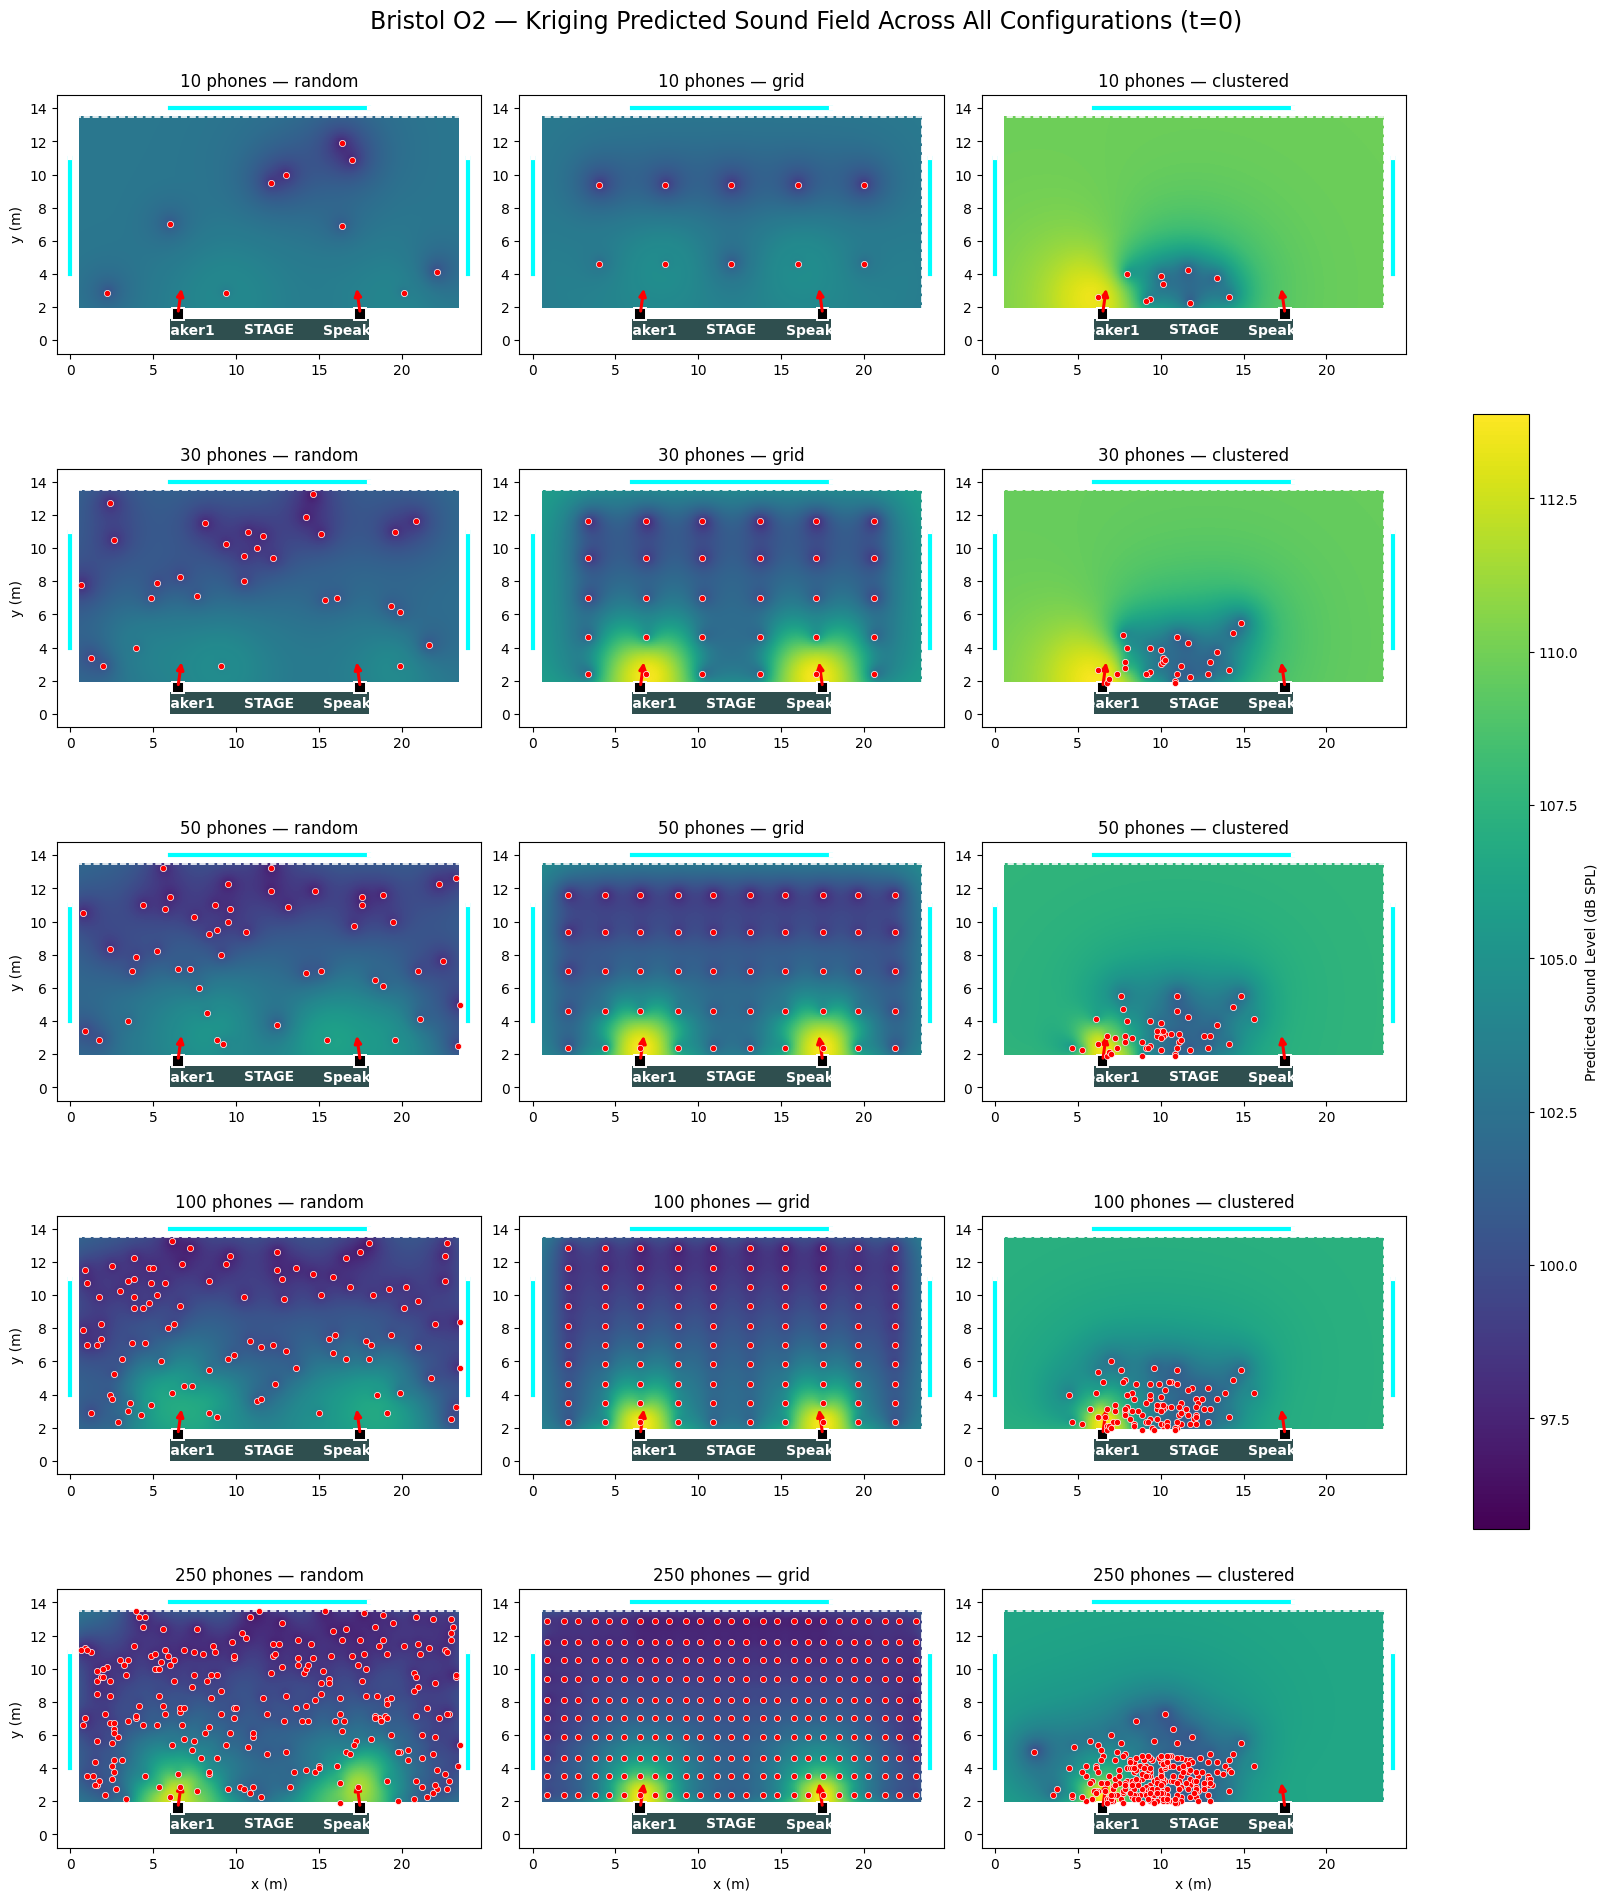

In [103]:
import inspect
import numpy as np
import matplotlib.pyplot as plt

# 1. Choose the venue sound map
import Working_final_maps.concert_map as sound_map
# import Working_final_maps.stadium_map as sound_map

from Working_final_maps.extract_sound_venues import prepare_interpolation_data

# NOTE: Ensure your Kriging class is imported!
# from Ordinary_Kriging_Model import ExactAcousticKriging

# ==========================================
# HELPER FUNCTION: DRAW VENUE
# ==========================================
def draw_venue(ax):
    """Draw the venue layout safely for both concert and stadium models."""
    if "treated" in inspect.signature(sound_map.draw_venue).parameters:
        sound_map.draw_venue(ax, treated=True)
    else:
        sound_map.draw_venue(ax)

# ==========================================
# 1. LOAD DATA & PREPARE
# ==========================================
sound_maps, x, y, allowed_mask = sound_map.load_sound_map()

sound_maps = np.asarray(sound_maps)
x = np.asarray(x)
y = np.asarray(y)
mask_2d = np.asarray(allowed_mask, dtype=bool)
grid_shape = (len(y), len(x))
mask_2d_grid = mask_2d.reshape(grid_shape)

venue_name = "Stadium" if "stadium" in sound_map.__name__ else "Bristol O2"

phone_counts = [10, 30, 50, 100, 250]
layouts = ["random", "grid", "clustered"]

prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x, y=y,
    phone_counts=phone_counts,
    layouts=layouts,
    seed=42,
    allowed_mask=allowed_mask
)

# Initialize Kriging Model (with the smart buffer enabled)
Kriging_Model = ExactAcousticKriging(safety_margin_db=3.0)


# ==========================================
# 2. BENCHMARKING & PREDICTION CACHING
# ==========================================
print(f"=== Running Benchmarks & Predictions for {venue_name} ===")
results = []
pred_maps_dict = {}

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]
        
        phone_levels = np.atleast_2d(data["phone_levels"])
        true_levels = np.atleast_2d(data["true_levels"])
        
        # Run Kriging prediction across time steps: shape (T, M)
        predicted_levels = Kriging_Model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=phone_levels,
            query_positions=data["query_positions"],
        )

        # Compute benchmark stats
        error = predicted_levels - true_levels
        audience_rmse = np.sqrt(np.mean(error ** 2))
        
        under_mask = error < 0 
        max_under_db = np.abs(np.min(error)) if np.any(under_mask) else 0.0

        results.append({
            "count": count, "layout": layout, 
            "rmse": audience_rmse, "max_under_db": max_under_db
        })
        
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {audience_rmse:.2f} dB | Worst Under: {max_under_db:.2f} dB")

        # Unpack time step 0 prediction back onto the full 2D canvas for plotting
        pred_2d = np.full(grid_shape, np.nan)
        pred_2d[mask_2d_grid] = predicted_levels[0] # Time step 0
        pred_maps_dict[(count, layout)] = pred_2d


# ==========================================
# 3. 15-PANEL PREDICTED SOUND MAP VISUALIZATION
# ==========================================
fig, axes = plt.subplots(len(phone_counts), len(layouts), figsize=(16, 19), constrained_layout=True)

# Find global color scale limits across all predictions for consistent color mapping
all_preds_flat = np.concatenate([m[~np.isnan(m)] for m in pred_maps_dict.values()])
vmin = float(np.min(all_preds_flat))
vmax = float(np.max(all_preds_flat))

for i, n in enumerate(phone_counts):
    for j, configuration in enumerate(layouts):
        ax = axes[i, j]
        pred_2d = pred_maps_dict[(n, configuration)]
        positions = prepared_data[(n, configuration)]["phone_positions"]

        # Plot only the Kriging predicted sound field
        im = ax.imshow(
            pred_2d, origin="lower", 
            extent=[x.min(), x.max(), y.min(), y.max()], 
            vmin=vmin, vmax=vmax, cmap="viridis"
        )

        draw_venue(ax)

        # Show the microphone positions in red
        ax.scatter(
            positions[:, 0], positions[:, 1],
            c="red", s=20, edgecolors="white",
            linewidths=0.5, zorder=10
        )

        ax.set_title(f"{n} phones — {configuration}")

        if i != len(phone_counts) - 1:
            ax.set_xlabel("")

        if j != 0:
            ax.set_ylabel("")

# Add one unified color bar for all subplots
fig.colorbar(im, ax=axes, label="Predicted Sound Level (dB SPL)", shrink=0.6)
fig.suptitle(f"{venue_name} — Kriging Predicted Sound Field Across All Configurations (t=0)", fontsize=17)

plt.savefig("all_predicted_sound_maps.png", dpi=180, bbox_inches="tight")
plt.show()

With buffer

--- Benchmarking Bristol O2 ---
Phones:  10 | Layout: random     | RMSE: 4.32 dB | Worst Under-Prediction: 9.26 dB
Phones:  10 | Layout: grid       | RMSE: 4.40 dB | Worst Under-Prediction: 8.75 dB
Phones:  10 | Layout: clustered  | RMSE: 10.84 dB | Worst Under-Prediction: 3.84 dB
Phones:  30 | Layout: random     | RMSE: 3.13 dB | Worst Under-Prediction: 9.21 dB
Phones:  30 | Layout: grid       | RMSE: 4.68 dB | Worst Under-Prediction: 0.00 dB
Phones:  30 | Layout: clustered  | RMSE: 10.42 dB | Worst Under-Prediction: 4.31 dB
Phones:  50 | Layout: random     | RMSE: 2.72 dB | Worst Under-Prediction: 8.55 dB
Phones:  50 | Layout: grid       | RMSE: 3.32 dB | Worst Under-Prediction: 0.00 dB
Phones:  50 | Layout: clustered  | RMSE: 8.38 dB | Worst Under-Prediction: 5.90 dB
Phones: 100 | Layout: random     | RMSE: 2.27 dB | Worst Under-Prediction: 6.69 dB
Phones: 100 | Layout: grid       | RMSE: 2.41 dB | Worst Under-Prediction: 0.00 dB
Phones: 100 | Layout: clustered  | RMSE: 7.95 dB | Wo

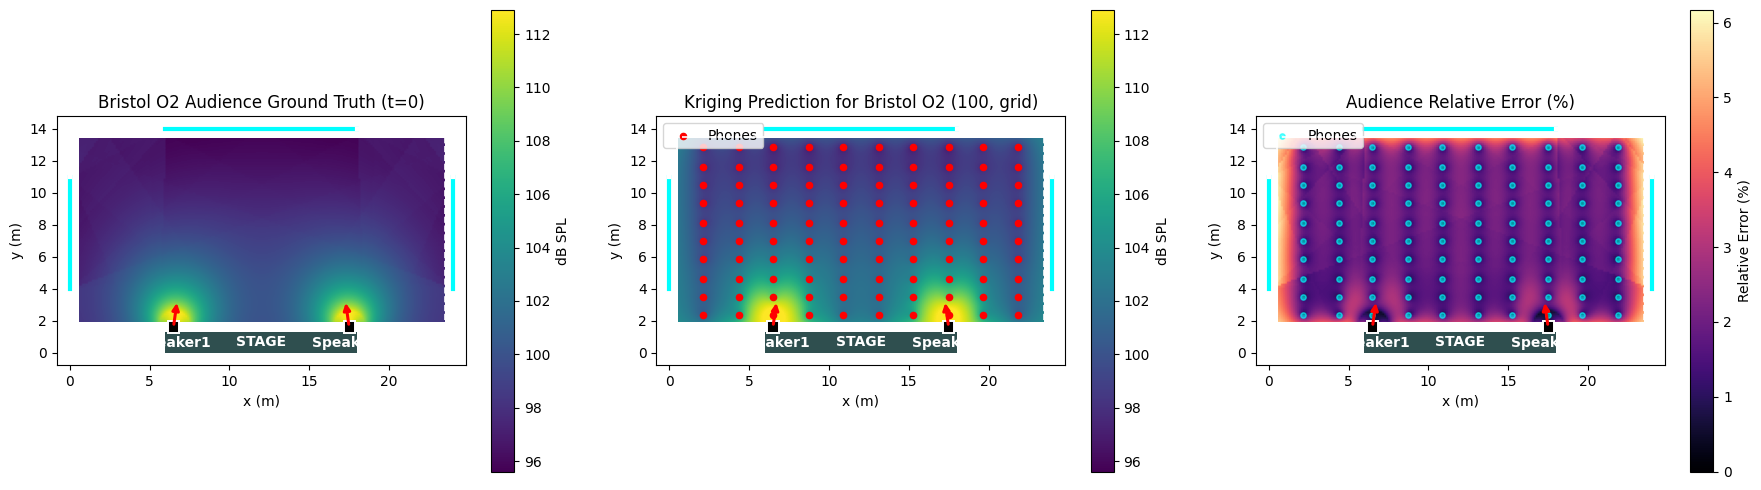

In [107]:
import inspect
import numpy as np
import matplotlib.pyplot as plt

# 1. Choose the venue sound map
import Working_final_maps.concert_map as sound_map
#import Working_final_maps.stadium_map as sound_map

from Working_final_maps.extract_sound_venues import prepare_interpolation_data

# NOTE: Ensure your Kriging class is imported!
# from Ordinary_Kriging_Model import ExactAcousticKriging

# ==========================================
# HELPER FUNCTION: DRAW VENUE
# ==========================================
def draw_venue(ax):
    """Draw the venue layout, handling the different drawing functions used by the stadium and concert models."""
    if "treated" in inspect.signature(sound_map.draw_venue).parameters:
        sound_map.draw_venue(ax, treated=True)
    else:
        sound_map.draw_venue(ax)

# ==========================================
# 1. LOAD DATA & PREPARE
# ==========================================
sound_maps, x, y, allowed_mask = sound_map.load_sound_map()
grid_shape = (len(y), len(x))
venue_name = "Stadium" if "stadium" in sound_map.__name__ else "Bristol O2"

phone_counts = [10, 30, 50, 100, 250]
layouts = ["random", "grid", "clustered"]

prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts,
    seed=42,
    allowed_mask=allowed_mask
)

# Initialize your Kriging Model (with the smart buffer!)
Kriging_Model = ExactAcousticKriging(safety_margin_db=3.0)

# ==========================================
# 2. BENCHMARKING
# ==========================================
print(f"--- Benchmarking {venue_name} ---")
results = []
rmse_values = []
count_layout_pairs = [(count, layout) for count in phone_counts for layout in layouts]

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]

        phone_levels = np.atleast_2d(data["phone_levels"])
        true_levels = np.atleast_2d(data["true_levels"])
        
        predicted_levels = Kriging_Model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"],
        )

        error = predicted_levels - true_levels
        audience_rmse = np.sqrt(np.mean(error ** 2))
        
        # Safety Metrics
        under_mask = error < 0 
        max_under_db = np.abs(np.min(error)) if np.any(under_mask) else 0.0

        results.append({
            "count": count, "layout": layout, 
            "rmse": audience_rmse, "max_under_db": max_under_db
        })
        
        rmse_values.append(audience_rmse)
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {audience_rmse:.2f} dB | Worst Under-Prediction: {max_under_db:.2f} dB")

print(rmse_values)


# ==========================================
# 3. 3-PANEL VISUALIZATION WITH VENUE OVERLAYS
# ==========================================
N_phones = 100
layout_type = "grid"

target_config = prepared_data[(N_phones, layout_type)]
target_true_levels = np.atleast_2d(target_config["true_levels"])
mask_2d = np.asarray(target_config["allowed_mask"]).reshape(grid_shape)

# Predict specifically for this layout
pred_map = Kriging_Model.fit_predict(
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Unpack audience points back into full 2D grids
ground_truth_2d = np.full(grid_shape, np.nan)
reconstructed_2d = np.full(grid_shape, np.nan)

ground_truth_2d[mask_2d] = target_true_levels[0]
reconstructed_2d[mask_2d] = pred_map[0]

# Compute Relative Error (%)
relative_error_2d = (np.abs(reconstructed_2d - ground_truth_2d) / np.abs(ground_truth_2d)) * 100

vmin = np.nanmin(ground_truth_2d)
vmax = np.nanmax(ground_truth_2d)

# Create the figure BEFORE trying to plot anything
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- PANEL 1: Ground Truth ---
im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax, cmap="viridis")
axes[0].set_title(f"{venue_name} Audience Ground Truth (t=0)")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
draw_venue(axes[0])  # <--- Apply template drawing!
plt.colorbar(im0, ax=axes[0], label="dB SPL")

# --- PANEL 2: Reconstruction ---
im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax, cmap="viridis")
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction for {venue_name} ({N_phones}, {layout_type})")
axes[1].set_xlabel("x (m)")
draw_venue(axes[1])  # <--- Apply template drawing!
axes[1].legend(loc="upper left")
plt.colorbar(im1, ax=axes[1], label="dB SPL")

# --- PANEL 3: Relative Error ---
im2 = axes[2].imshow(relative_error_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="magma", vmin=0)
axes[2].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="cyan", s=15, alpha=0.6, label="Phones")
axes[2].set_title("Audience Relative Error (%)")
axes[2].set_xlabel("x (m)")
draw_venue(axes[2])  # <--- Apply template drawing!
axes[2].legend(loc="upper left")
plt.colorbar(im2, ax=axes[2], label="Relative Error (%)")

plt.tight_layout()
plt.show()

without buffer

--- Benchmarking Stadium ---
Phones:  10 | Layout: random     | RMSE: 1.32 dB | Worst Under-Prediction: 10.25 dB
Phones:  10 | Layout: grid       | RMSE: 1.32 dB | Worst Under-Prediction: 11.45 dB
Phones:  10 | Layout: clustered  | RMSE: 1.66 dB | Worst Under-Prediction: 12.29 dB
Phones:  30 | Layout: random     | RMSE: 1.30 dB | Worst Under-Prediction: 8.44 dB
Phones:  30 | Layout: grid       | RMSE: 1.19 dB | Worst Under-Prediction: 7.21 dB
Phones:  30 | Layout: clustered  | RMSE: 1.55 dB | Worst Under-Prediction: 12.45 dB
Phones:  50 | Layout: random     | RMSE: 1.13 dB | Worst Under-Prediction: 7.66 dB
Phones:  50 | Layout: grid       | RMSE: 1.14 dB | Worst Under-Prediction: 6.28 dB
Phones:  50 | Layout: clustered  | RMSE: 1.51 dB | Worst Under-Prediction: 12.68 dB
Phones: 100 | Layout: random     | RMSE: 1.00 dB | Worst Under-Prediction: 6.66 dB
Phones: 100 | Layout: grid       | RMSE: 1.00 dB | Worst Under-Prediction: 5.57 dB
Phones: 100 | Layout: clustered  | RMSE: 1.56 dB | Wo

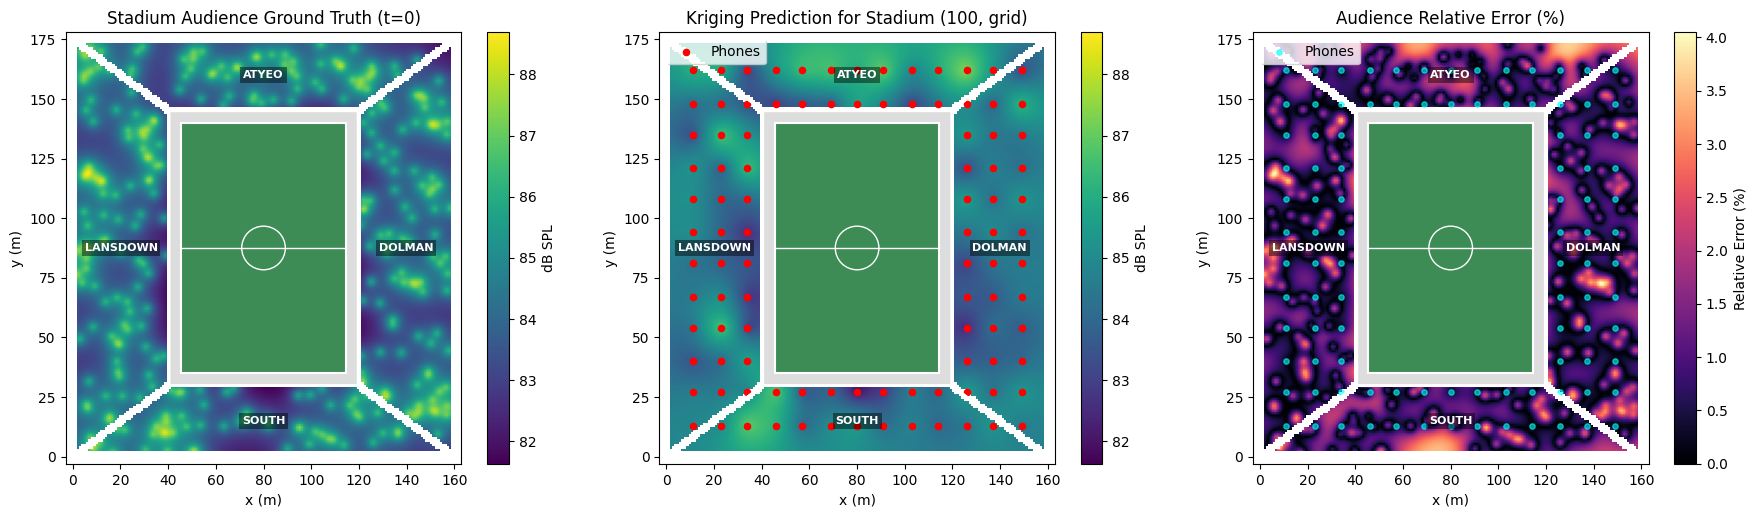

In [97]:
import inspect
import numpy as np
import matplotlib.pyplot as plt

# 1. Choose the venue sound map
#import Working_final_maps.concert_map as sound_map
import Working_final_maps.stadium_map as sound_map

from Working_final_maps.extract_sound_venues import prepare_interpolation_data

# NOTE: Ensure your Kriging class is imported!
from Ordinary_Kriging_Model import ExactAcousticKriging
No_buffer_Kriging_Model = ExactAcousticKriging(safety_margin_db=0.0)  # No buffer for comparison

# ==========================================
# HELPER FUNCTION: DRAW VENUE
# ==========================================
def draw_venue(ax):
    """Draw the venue layout, handling the different drawing functions used by the stadium and concert models."""
    if "treated" in inspect.signature(sound_map.draw_venue).parameters:
        sound_map.draw_venue(ax, treated=True)
    else:
        sound_map.draw_venue(ax)

# ==========================================
# 1. LOAD DATA & PREPARE
# ==========================================
sound_maps, x, y, allowed_mask = sound_map.load_sound_map()
grid_shape = (len(y), len(x))
venue_name = "Stadium" if "stadium" in sound_map.__name__ else "Bristol O2"

phone_counts = [10, 30, 50, 100, 250]
layouts = ["random", "grid", "clustered"]

prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts,
    seed=42,
    allowed_mask=allowed_mask
)


# ==========================================
# 2. BENCHMARKING
# ==========================================
print(f"--- Benchmarking {venue_name} ---")
results = []

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]

        phone_levels = np.atleast_2d(data["phone_levels"])
        true_levels = np.atleast_2d(data["true_levels"])
        
        predicted_levels = No_buffer_Kriging_Model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"],
        )

        error = predicted_levels - true_levels
        audience_rmse = np.sqrt(np.mean(error ** 2))
        
        # Safety Metrics
        under_mask = error < 0 
        max_under_db = np.abs(np.min(error)) if np.any(under_mask) else 0.0

        results.append({
            "count": count, "layout": layout, 
            "rmse": audience_rmse, "max_under_db": max_under_db
        })
        
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {audience_rmse:.2f} dB | Worst Under-Prediction: {max_under_db:.2f} dB")


# ==========================================
# 3. 3-PANEL VISUALIZATION WITH VENUE OVERLAYS
# ==========================================
N_phones = 100
layout_type = "grid"

target_config = prepared_data[(N_phones, layout_type)]
target_true_levels = np.atleast_2d(target_config["true_levels"])
mask_2d = np.asarray(target_config["allowed_mask"]).reshape(grid_shape)

# Predict specifically for this layout
pred_map = No_buffer_Kriging_Model.fit_predict(
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Unpack audience points back into full 2D grids
ground_truth_2d = np.full(grid_shape, np.nan)
reconstructed_2d = np.full(grid_shape, np.nan)

ground_truth_2d[mask_2d] = target_true_levels[0]
reconstructed_2d[mask_2d] = pred_map[0]

# Compute Relative Error (%)
relative_error_2d = (np.abs(reconstructed_2d - ground_truth_2d) / np.abs(ground_truth_2d)) * 100

vmin = np.nanmin(ground_truth_2d)
vmax = np.nanmax(ground_truth_2d)

# Create the figure BEFORE trying to plot anything
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- PANEL 1: Ground Truth ---
im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax, cmap="viridis")
axes[0].set_title(f"{venue_name} Audience Ground Truth (t=0)")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
draw_venue(axes[0])  # <--- Apply template drawing!
plt.colorbar(im0, ax=axes[0], label="dB SPL")

# --- PANEL 2: Reconstruction ---
im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax, cmap="viridis")
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction for {venue_name} ({N_phones}, {layout_type})")
axes[1].set_xlabel("x (m)")
draw_venue(axes[1])  # <--- Apply template drawing!
axes[1].legend(loc="upper left")
plt.colorbar(im1, ax=axes[1], label="dB SPL")

# --- PANEL 3: Relative Error ---
im2 = axes[2].imshow(relative_error_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="magma", vmin=0)
axes[2].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="cyan", s=15, alpha=0.6, label="Phones")
axes[2].set_title("Audience Relative Error (%)")
axes[2].set_xlabel("x (m)")
draw_venue(axes[2])  # <--- Apply template drawing!
axes[2].legend(loc="upper left")
plt.colorbar(im2, ax=axes[2], label="Relative Error (%)")

plt.tight_layout()
plt.show()

with diffusion

Phones:  10 | Layout: random     | RMSE: 6.04 dB | Worst Under-Prediction: 4.45 dB
Phones:  10 | Layout: grid       | RMSE: 5.90 dB | Worst Under-Prediction: 5.45 dB
Phones:  10 | Layout: clustered  | RMSE: 6.57 dB | Worst Under-Prediction: 6.29 dB
Phones:  30 | Layout: random     | RMSE: 5.09 dB | Worst Under-Prediction: 2.80 dB
Phones:  30 | Layout: grid       | RMSE: 5.51 dB | Worst Under-Prediction: 1.80 dB
Phones:  30 | Layout: clustered  | RMSE: 6.06 dB | Worst Under-Prediction: 6.45 dB
Phones:  50 | Layout: random     | RMSE: 5.17 dB | Worst Under-Prediction: 2.43 dB
Phones:  50 | Layout: grid       | RMSE: 5.17 dB | Worst Under-Prediction: 2.05 dB
Phones:  50 | Layout: clustered  | RMSE: 5.67 dB | Worst Under-Prediction: 6.68 dB
Phones: 100 | Layout: random     | RMSE: 4.73 dB | Worst Under-Prediction: 2.20 dB
Phones: 100 | Layout: grid       | RMSE: 4.46 dB | Worst Under-Prediction: 1.88 dB
Phones: 100 | Layout: clustered  | RMSE: 5.86 dB | Worst Under-Prediction: 6.58 dB
Phon

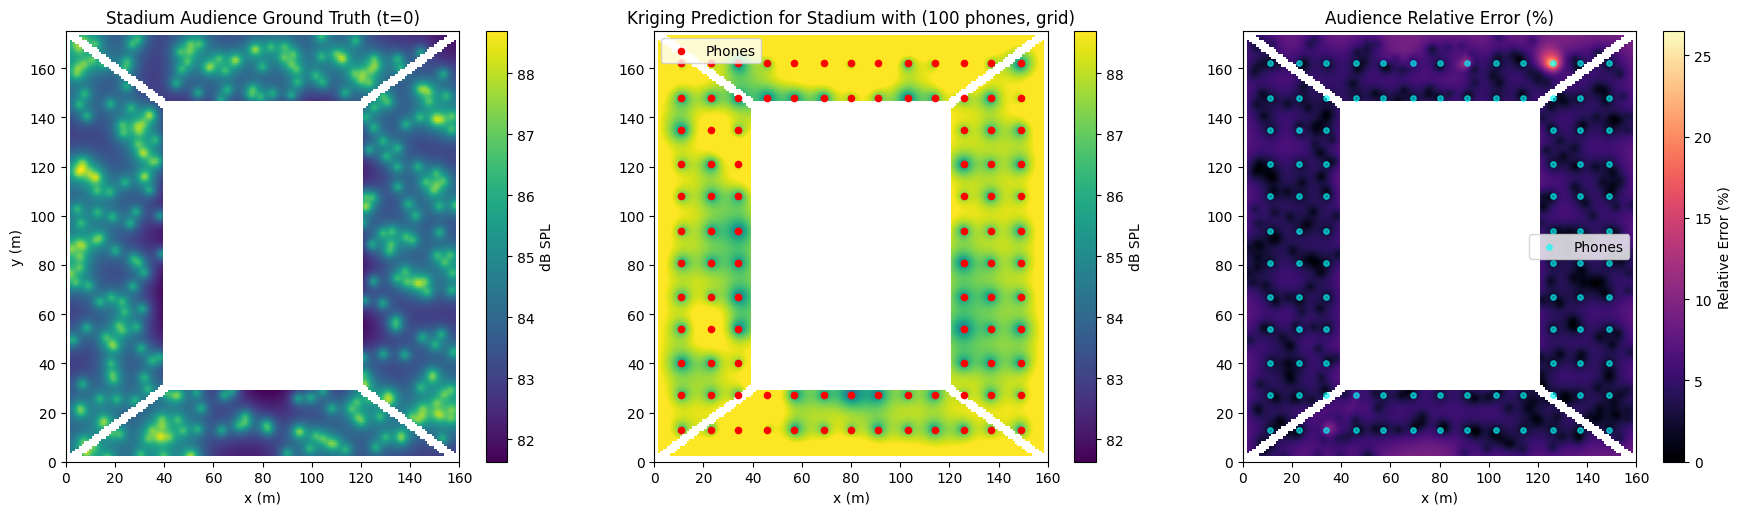

In [83]:
""" Example of how to load the sound map and prepare microphone measurements for interpolation."""

# uncomment the appropriate line below to choose the venue sound map
#import concert_map as sound_map
import Working_final_maps.stadium_map as sound_map

from Working_final_maps.extract_sound_venues import prepare_interpolation_data

from Ordinary_Kriging_Model import ExactAcousticKriging

Kriging_Model = ExactAcousticKriging(safety_margin_db=6.0, peak_boost=True)


# load the simulated sound map and audience area
sound_maps, x, y, allowed_mask = sound_map.load_sound_map()

grid_shape = (len(y), len(x))

# number of phones and layouts to compare
phone_counts = [10, 30, 50, 100, 250]
layouts = ["random", "grid", "clustered"]

# generate phone positions and extract their sound measurements
prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts,
    seed=42,
    allowed_mask=allowed_mask)




#2. Define phone configurations
phone_counts = [10, 30, 50, 100, 250]
layouts = ["random", "grid", "clustered"]

#3. Track benchmarking results
results = []

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]

        # Ensure 2D inputs
        phone_levels = np.atleast_2d(data["phone_levels"])
        true_levels = np.atleast_2d(data["true_levels"])
        
        # Run interpolation
        predicted_levels = Kriging_Model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"],
        )

        # 1. Standard RMSE (Will be higher with a buffer)
        error = predicted_levels - true_levels
        audience_rmse = np.sqrt(np.mean(error ** 2))
        
        # 2. Safety Metrics (The buffer's true purpose)
        # Find only the pixels where we UNDERESTIMATED the true sound
        under_mask = error < 0 
        
        if np.any(under_mask):
            mean_under_db = np.abs(np.mean(error[under_mask]))
            max_under_db = np.abs(np.min(error)) # The most dangerous miss
        else:
            mean_under_db = 0.0
            max_under_db = 0.0

        results.append({
            "count": count, 
            "layout": layout, 
            "rmse": audience_rmse,
            "max_under_db": max_under_db
        })
        
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {audience_rmse:.2f} dB | Worst Under-Prediction: {max_under_db:.2f} dB")

N_phones = 100
layout_type = "grid"

# 4. Visualize a specific reconstruction (Time step 0 for 20 clustered phones)
target_config = prepared_data[(N_phones, layout_type)]
target_phone_levels = np.atleast_2d(target_config["phone_levels"])
target_true_levels = np.atleast_2d(target_config["true_levels"])
mask_2d = np.asarray(target_config["allowed_mask"]).reshape(grid_shape)

pred_map = Kriging_Model.fit_predict(
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Unpack audience points back into full (len(y), len(x)) grids
ground_truth_2d = np.full(grid_shape, np.nan)
reconstructed_2d = np.full(grid_shape, np.nan)

ground_truth_2d[mask_2d] = target_true_levels[0]
reconstructed_2d[mask_2d] = pred_map[0]

# Compute Relative Error (%)
relative_error_2d = (np.abs(reconstructed_2d - ground_truth_2d) / np.abs(ground_truth_2d)) * 100

# nanmin/nanmax ensure NaNs outside the audience don't corrupt color limits
vmin = np.nanmin(ground_truth_2d)
vmax = np.nanmax(ground_truth_2d)

#Plot figures
#1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax, cmap="viridis")
axes[0].set_title("Stadium Audience Ground Truth (t=0)")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
plt.colorbar(im0, ax=axes[0], label="dB SPL")

im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax, cmap="viridis")
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction for Stadium with ({N_phones} phones, {layout_type})")
axes[1].set_xlabel("x (m)")
axes[1].legend(loc="upper left")
plt.colorbar(im1, ax=axes[1], label="dB SPL")

im2 = axes[2].imshow(relative_error_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="magma", vmin=0)
axes[2].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="cyan", s=15, alpha=0.6, label="Phones")
axes[2].set_title("Audience Relative Error (%)")
axes[2].set_xlabel("x (m)")
axes[2].legend()
plt.colorbar(im2, ax=axes[2], label="Relative Error (%)")


plt.tight_layout()
plt.show()